<a href="https://colab.research.google.com/github/Jaek-Hxiang/Portfolio/blob/main/Max%20Return%20Portfolio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor,GradientBoostingRegressor, AdaBoostRegressor
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, BayesianRidge
from sklearn.metrics import (accuracy_score,auc,classification_report,confusion_matrix,
                             ConfusionMatrixDisplay,f1_score,mean_absolute_error,mean_squared_error,precision_score,
                             r2_score,recall_score,roc_auc_score,roc_curve,RocCurveDisplay)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree,DecisionTreeRegressor
from sklearn.utils.class_weight import compute_class_weight
from scipy import stats


df = pd.read_csv("adjprice.csv", index_col = False, sep = ',')

#EDA and Data Cleaning

In [ ]:
print(df.shape)
print(df.info)
print(df.describe)

(9459, 1200)
<bound method DataFrame.info of           Date  0111145D US Equity  0202445Q US Equity  0203524D US Equity  \
0     19930907             13.2719             13.6829              8.4429   
1     19930908             13.3263             13.5315              8.2147   
2     19930909             13.7070             13.3800              8.7852   
3     19930910             13.3807             13.4810              9.4127   
4     19930911             13.3807             13.4810              9.4127   
...        ...                 ...                 ...                 ...   
9454  20190727                 NaN                 NaN                 NaN   
9455  20190728                 NaN                 NaN                 NaN   
9456  20190729                 NaN                 NaN                 NaN   
9457  20190730                 NaN                 NaN                 NaN   
9458  20190731                 NaN                 NaN                 NaN   

      0226226D US 

In [ ]:
print(df.head(5))

       Date  0111145D US Equity  0202445Q US Equity  0203524D US Equity  \
0  19930907             13.2719             13.6829              8.4429   
1  19930908             13.3263             13.5315              8.2147   
2  19930909             13.7070             13.3800              8.7852   
3  19930910             13.3807             13.4810              9.4127   
4  19930911             13.3807             13.4810              9.4127   

   0226226D US Equity  0376152D US Equity  0440296D US Equity  \
0              8.1042              11.000             57.3245   
1              7.9590              11.000             57.2096   
2              8.0627              11.125             59.1625   
3              8.0368              11.125             59.6220   
4              8.0368              11.125             59.6220   

   0544749D US Equity  0574018D US Equity  0598884D US Equity  ...  \
0             17.8887              6.8315             28.1246  ...   
1             17.8

In [ ]:
print(df.tail(10))

          Date  0111145D US Equity  0202445Q US Equity  0203524D US Equity  \
9449  20190722                 NaN                 NaN                 NaN   
9450  20190723                 NaN                 NaN                 NaN   
9451  20190724                 NaN                 NaN                 NaN   
9452  20190725                 NaN                 NaN                 NaN   
9453  20190726                 NaN                 NaN                 NaN   
9454  20190727                 NaN                 NaN                 NaN   
9455  20190728                 NaN                 NaN                 NaN   
9456  20190729                 NaN                 NaN                 NaN   
9457  20190730                 NaN                 NaN                 NaN   
9458  20190731                 NaN                 NaN                 NaN   

      0226226D US Equity  0376152D US Equity  0440296D US Equity  \
9449                 NaN                 NaN                 NaN   
9450 

In [ ]:
print(df.isnull().sum())

Date                     0
0111145D US Equity    2505
0202445Q US Equity    3237
0203524D US Equity    2505
0226226D US Equity    3603
                      ... 
ZETHQ US Equity       6897
ZION US Equity           0
ZRN US Equity         7629
ZTS US Equity         7086
ZTS-W US Equity       9364
Length: 1200, dtype: int64


In [ ]:
null_counts = df.isnull().sum()
non_null_percentages = (df.count() / len(df)) * 100

# Create a DataFrame to hold this information for easier sorting and filtering
column_info = pd.DataFrame({
    'null_count': null_counts,
    'non_null_percentage': non_null_percentages
})

# Sort by null_count in descending order to prepare for the output
column_info = column_info.sort_values(by='null_count', ascending=True)

# Define the three parts based on non_null_percentage
part1_cols = column_info[column_info['non_null_percentage'] >= 90]
part2_cols = column_info[(column_info['non_null_percentage'] >= 70) & (column_info['non_null_percentage'] < 90)]
part3_cols = column_info[(column_info['non_null_percentage'] >= 50) & (column_info['non_null_percentage'] < 70)]
part4_cols = column_info[(column_info['non_null_percentage'] >= 30) & (column_info['non_null_percentage'] < 50)]
part5_cols = column_info[column_info['non_null_percentage'] < 30]


print("--- Columns with 90% or more non-null values ---")
print(f"Total columns: {len(part1_cols)}")
if not part1_cols.empty:
    for col_name, row in part1_cols.iterrows():
        print(f"- {col_name} (Nulls: {int(row['null_count'])}, Non-null %: {row['non_null_percentage']:.2f}%) Kishan")
print("\n")

print("--- Columns with 70% to 89% non-null values ---")
print(f"Total columns: {len(part2_cols)}")
if not part2_cols.empty:
    for col_name, row in part2_cols.iterrows():
        print(f"- {col_name} (Nulls: {int(row['null_count'])}, Non-null %: {row['non_null_percentage']:.2f}%) Kishan")
print("\n")

print("--- Columns with 50% to 69% non-null values ---")
print(f"Total columns: {len(part3_cols)}")
if not part3_cols.empty:
    for col_name, row in part3_cols.iterrows():
        print(f"- {col_name} (Nulls: {int(row['null_count'])}, Non-null %: {row['non_null_percentage']:.2f}%) Kishan")
print("\n")

print("--- Columns with 30% to 49% non-null values ---")
print(f"Total columns: {len(part4_cols)}")
if not part4_cols.empty:
    for col_name, row in part4_cols.iterrows():
        print(f"- {col_name} (Nulls: {int(row['null_count'])}, Non-null %: {row['non_null_percentage']:.2f}%) Kishan")
print("\n")

print("--- Columns with 0% to 29% non-null values ---")
print(f"Total columns: {len(part5_cols)}")
if not part5_cols.empty:
    for col_name, row in part5_cols.iterrows():
        print(f"- {col_name} (Nulls: {int(row['null_count'])}, Non-null %: {row['non_null_percentage']:.2f}%) Kishan")



--- Columns with 90% or more non-null values ---
Total columns: 458
- AZO US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BHGE US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BGG US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BF/B US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BEN US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BDX US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BCO US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BC US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BBY US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- NEU US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BBBY US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BAX US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BAC US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- BA US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- GT US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- AXP US Equity (Nulls: 0, Non-null %: 100.00%) Kishan
- AVY US Equity (Nulls: 0, Non-null %: 100.00%) Kish

I could possibly use high nonnulls equities to create graphs and determine there growth in value over time,
however what happens to the equities with low nonnulls?
reasons for it being low nonnull:
1. missing data
2. it is a short term equity

In [ ]:
# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'], format='%Y%m%d')

# Set Date as index
df = df.set_index('Date')

# Check result
df.head()

,0111145D US Equity,0202445Q US Equity,0203524D US Equity,0226226D US Equity,0376152D US Equity,0440296D US Equity,0544749D US Equity,0574018D US Equity,0598884D US Equity,0772031D US Equity,...,YNR US Equity,YRCW US Equity,YUM US Equity,YUMC US Equity,ZBH US Equity,ZETHQ US Equity,ZION US Equity,ZRN US Equity,ZTS US Equity,ZTS-W US Equity
Date,,,,,,,,,,,,,,,,,,,,,
1993-09-07,13.2719,13.6829,8.4429,8.1042,11.000,57.3245,17.8887,6.8315,28.1246,NaN,...,NaN,144439.5121,NaN,NaN,NaN,6.875,7.1675,30.7970,NaN,NaN
1993-09-08,13.3263,13.5315,8.2147,7.9590,11.000,57.2096,17.8064,6.8315,27.5051,NaN,...,NaN,143691.1208,NaN,NaN,NaN,6.750,6.9766,30.0188,NaN,NaN
1993-09-09,13.7070,13.3800,8.7852,8.0627,11.125,59.1625,17.6831,6.8315,27.7529,NaN,...,NaN,143691.1208,NaN,NaN,NaN,6.625,6.9554,30.0188,NaN,NaN
1993-09-10,13.3807,13.4810,9.4127,8.0368,11.125,59.6220,17.6420,6.8773,27.5051,NaN,...,NaN,145187.9033,NaN,NaN,NaN,6.750,7.2099,29.6852,NaN,NaN
1993-09-11,13.3807,13.4810,9.4127,8.0368,11.125,59.6220,17.6420,6.8773,27.5051,NaN,...,NaN,145187.9033,NaN,NaN,NaN,6.750,7.2099,29.6852,NaN,NaN


In [ ]:
# Investigate suspicious tickers

q_cols = [c for c in df.columns if 'Q' in c]
w_cols = [c for c in df.columns if '-W' in c]

print("Number of 'Q' columns:", len(q_cols))
print("Number of '-W' columns:", len(w_cols))

print("\nSample 'Q' columns:", q_cols[:5])
print("Sample '-W' columns:", w_cols[:5])

Number of 'Q' columns: 240
Number of '-W' columns: 2

Sample 'Q' columns: ['0202445Q US Equity', '1028411Q US Equity', '1166Q US Equity', '1199Q US Equity', '1237Q US Equity']
Sample '-W' columns: ['MJN-W US Equity', 'ZTS-W US Equity']


In [ ]:
# Improved filtering

cols = [c for c in df.columns if 'US Equity' in c]

clean_cols = [
    c for c in cols
    if ('-W' not in c) and ('Q' not in c)
]

df = df[clean_cols]

print("Remaining columns:", len(df.columns))

Remaining columns: 957


In [ ]:
print("Original shape:", df.shape)
# Keep stocks with at least 80% non-missing data

threshold = int(0.8 * len(df))
df = df.dropna(axis=1, thresh=threshold)


# Check new shape
print("Filtered shape:", df.shape)

Original shape: (9459, 957)
Filtered shape: (9459, 547)


In [ ]:
import time
import logging
import requests
import pandas as pd
import yfinance as yf
from tqdm import tqdm

import warnings
warnings.filterwarnings('ignore')

# Also suppress yfinance's own warnings:
import logging
logging.getLogger('yfinance').setLevel(logging.ERROR)

# ─ CONFIG ────────────────────────────────────────────
DATE_COLUMN      = "Date"                      # <- the date/index column name
OUTPUT_LOOKUP    = "classified_equities.csv"   # ticker -> sector lookup
OUTPUT_ANNOTATED = "original_with_sectors.csv" # original + sector row

# Get your free API key at https://www.openfigi.com/user/signup
# With a key: 250 requests/min, batch size 100
# Without a key: 5 requests/min, batch size 10
OPENFIGI_API_KEY = "1d0170e7-3d21-4511-aa12-2753950fa247"   # <- paste your key here, e.g. "abc123xyz..."

YAHOO_DELAY      = 0.5
YAHOO_RETRIES    = 3
# ─────────────────────────────────────────────

# Rate limit settings ─ automatically adjusted based on whether you have a key
if OPENFIGI_API_KEY:
    FIGI_BATCH_SIZE  = 100   # max allowed with API key
    FIGI_DELAY       = 0.5   # 250 req/min with key ─ very fast
    FIGI_RETRY_DELAY = 15.0
else:
    FIGI_BATCH_SIZE  = 5     # safe batch size without key
    FIGI_DELAY       = 12.0  # ~5 req/min without key
FIGI_MAX_RETRIES = 5

OPENFIGI_URL = "https://api.openfigi.com/v3/mapping"

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
log = logging.getLogger(__name__)

# ─ 11 GICS sector mapping ───────────────────────────────────
YAHOO_TO_GICS = {
    "technology":             "Information Technology",
    "financial services":     "Financials",
    "financial":              "Financials",
    "healthcare":             "Health Care",
    "health care":            "Health Care",
    "consumer cyclical":      "Consumer Discretionary",
    "consumer discretionary": "Consumer Discretionary",
    "communication services": "Communication Services",
    "industrials":            "Industrials",
    "consumer defensive":     "Consumer Staples",
    "consumer staples":       "Consumer Staples",
    "energy":                 "Energy",
    "utilities":              "Utilities",
    "real estate":            "Real Estate",
    "basic materials":        "Materials",
    "materials":              "Materials",
}
VALID_SECTORS = set(YAHOO_TO_GICS.values())


# ─ Step 1: Bloomberg code -> ticker via OpenFIGI ───────────────────

def extract_bloomberg_code(col_name: str) -> str:
    """'0376152D US Equity' -> '0376152D'"""
    return col_name.replace(" US Equity", "").replace(" Equity", "").strip()


def build_headers() -> dict:
    headers = {"Content-Type": "application/json"}
    if OPENFIGI_API_KEY:
        headers["X-OPENFIGI-APIKEY"] = OPENFIGI_API_KEY
    return headers


def batch_figi_lookup(codes: list) -> dict:
    """
    Send a batch of Bloomberg codes to OpenFIGI.
    Returns dict: { bloomberg_code: ticker_symbol or None }
    """
    # Try these in order - most specific first
    id_types_to_try = [
        # 8-character codes (like 0574018D) - try this FIRST
        {"idType": "ID_BB_8_CHR", "params": {"exchCode": "US"}},
        # Then try as ticker symbol directly
        {"idType": "TICKER", "params": {"exchCode": "US", "marketSecDes": "Equity"}},
        # Then try general Bloomberg ID
        {"idType": "ID_BB", "params": {"exchCode": "US", "marketSecDes": "Equity"}},
        # Last resort: global ID without restrictions
        {"idType": "ID_BB_GLOBAL", "params": {}},
    ]

    for config in id_types_to_try:
        id_type = config["idType"]
        extra_params = config["params"]

        payload = []
        for code in codes:
            request_item = {"idType": id_type, "idValue": code}
            request_item.update(extra_params)
            payload.append(request_item)

        for attempt in range(1, FIGI_MAX_RETRIES + 1):
            try:
                resp = requests.post(
                    OPENFIGI_URL,
                    json=payload,
                    headers=build_headers(),
                    timeout=20,
                )

                if resp.status_code == 429:
                    wait = FIGI_RETRY_DELAY * attempt
                    log.warning(
                        f"429 Too Many Requests (attempt {attempt}/{FIGI_MAX_RETRIES}). "
                        f"Waiting {wait:.0f}s... "
                        f"{'Tip: add a free API key to raise your limit!' if not OPENFIGI_API_KEY else ''}"
                    )
                    time.sleep(wait)
                    continue

                resp.raise_for_status()
                results = resp.json()
                break  # success ─ exit retry loop

            except requests.exceptions.RequestException as exc:
                log.warning(f"Network error attempt {attempt}: {exc}")
                time.sleep(FIGI_RETRY_DELAY)
                continue
        else:
            # All retries failed for this idType ─ continue to the next one
            log.warning(f"All retries failed for idType={id_type}.")
            continue

        # Parse results with better filtering
        mapping = {}
        any_found = False
        for code, result in zip(codes, results):
            if "error" in result:
                mapping[code] = None
                continue

            data = result.get("data", [])
            if not data:
                mapping[code] = None
                continue

            any_found = True
            ticker = None

            # Priority 1: Active US equity on major exchanges
            for entry in data:
                if (entry.get("exchCode") in ("US", "UN", "UQ", "UA", "UR") and
                    entry.get("marketSecDes") == "Equity" and
                    entry.get("securityType2") != "Defunct"):
                    ticker = entry.get("ticker")
                    break

            # Priority 2: Any US exchange
            if not ticker:
                for entry in data:
                    if entry.get("exchCode") in ("US", "UN", "UQ", "UA", "UR"):
                        ticker = entry.get("ticker")
                        break

            # Priority 3: First available ticker
            if not ticker:
                ticker = data[0].get("ticker")

            mapping[code] = ticker

        if any_found:
            return mapping

    # If no tickers found across all attempts
    return {code: None for code in codes}
def resolve_tickers(bloomberg_cols: list) -> dict:
    """
    Convert all Bloomberg column names to real tickers.
    Saves progress to figi_progress.csv after every batch ─ re-running
    the script will skip already-resolved codes automatically.
    Returns dict: { original_col_name: ticker or None }
    """
    PROGRESS_FILE = "figi_progress.csv"

    try:
        progress_df  = pd.read_csv(PROGRESS_FILE)
        already_done = dict(zip(progress_df["bloomberg_code"], progress_df["ticker"]))
        log.info(f"Resuming ─ {len(already_done)} codes already resolved from {PROGRESS_FILE}.")
    except FileNotFoundError:
        already_done = {}

    code_map     = {col: extract_bloomberg_code(col) for col in bloomberg_cols}
    unique_codes = list(set(code_map.values()))
    pending      = [c for c in unique_codes if c not in already_done]

    if OPENFIGI_API_KEY:
        log.info("API key detected ─ using high rate limit (250 req/min, batch size 100).")
    else:
        log.warning(
            "No API key set. Using free rate limit (5 req/min). "
            "Get a free key at https://www.openfigi.com/user/signup to run ~20x faster."
        )

    n_batches   = (len(pending) + FIGI_BATCH_SIZE - 1) // FIGI_BATCH_SIZE
    est_minutes = (n_batches * FIGI_DELAY) / 60
    log.info(
        f"{len(unique_codes)} total | {len(already_done)} cached | {len(pending)} to fetch. "
        f"Est. time: ~{est_minutes:.1f} min"
    )

    resolved_this_run = {}
    for i in tqdm(range(0, len(pending), FIGI_BATCH_SIZE),
                  desc="OpenFIGI lookup", unit="batch"):
        batch  = pending[i: i + FIGI_BATCH_SIZE]
        result = batch_figi_lookup(batch)
        resolved_this_run.update(result)

        # Save progress after every batch
        all_resolved = {**already_done, **resolved_this_run}
        pd.DataFrame(
            [{"bloomberg_code": k, "ticker": v} for k, v in all_resolved.items()]
        ).to_csv(PROGRESS_FILE, index=False)

        if i + FIGI_BATCH_SIZE < len(pending):
            time.sleep(FIGI_DELAY)

    already_done.update(resolved_this_run)

    col_to_ticker = {col: already_done.get(code) for col, code in code_map.items()}
    failed = [col for col, tk in col_to_ticker.items() if not tk]
    if failed:
        log.warning(f"{len(failed)} codes could not be resolved.")
    return col_to_ticker


# ─ Step 2: ticker -> GICS sector via yfinance ─────────────────────────────────

def normalise_sector(raw: str) -> str:
    if not raw:
        return "Unclassified"
    return YAHOO_TO_GICS.get(raw.strip().lower(), f"Other: {raw.strip()}")

def is_valid_ticker_format(ticker: str) -> bool:
    """Quick validation of ticker format"""
    if not ticker or ticker == "UNRESOLVED":
        return False
    if len(ticker) > 10:  # Suspiciously long
        return False
    # Add more validation as needed
    return True


def fetch_sector(ticker: str) -> dict:
    """Fetch sector info with better error handling"""
    # Clean ticker format - handle special cases
    clean_ticker = ticker.replace("/", ".")  # BRK/B → BRK.B

    for attempt in range(YAHOO_RETRIES + 1):
        try:
            stock = yf.Ticker(clean_ticker)
            info = stock.info

            # Check if we got valid data
            if not info or len(info) < 5:  # Too small = error response
                raise ValueError("Empty or invalid response")

            raw = info.get("sector", "") or ""
            return {
                "name":         info.get("longName", ""),
                "yahoo_sector": raw,
                "sector":       normalise_sector(raw),
                "industry":     info.get("industry", ""),
                "exchange":     info.get("exchange", ""),
            }

        except Exception as exc:
            if attempt < YAHOO_RETRIES:
                wait_time = 2.0 * (attempt + 1)  # Exponential backoff
                log.debug(f"[{ticker}] Attempt {attempt + 1} failed: {exc}. Retrying in {wait_time}s...")
                time.sleep(wait_time)
            else:
                log.warning(f"[{ticker}] All Yahoo lookup attempts failed: {type(exc).__name__}")
                return {
                    "name": "",
                    "yahoo_sector": "",
                    "sector": "Unclassified",
                    "industry": "",
                    "exchange": "",
                }

    # Fallback (should never reach here)
    return {
        "name": "", "yahoo_sector": "", "sector": "Unclassified",
        "industry": "", "exchange": "",
    }


# ─ Main ────────────────────────────────────────

def main(df_to_process: pd.DataFrame):
    log.info("Using the pre-processed DataFrame.")

    # The DATE_COLUMN is now the index after previous cleaning steps
    date_col = df_to_process.index.name

    # Exclude the index (Date) column when identifying Bloomberg columns
    bloomberg_cols = [c for c in df_to_process.columns if c != date_col]
    log.info(f"Found {len(bloomberg_cols)} Bloomberg-format columns in the provided DataFrame.")

    # Step 1: Bloomberg codes -> tickers
    col_to_ticker = resolve_tickers(bloomberg_cols)

    # Step 2: tickers -> GICS sectors
    log.info("Fetching sector data from Yahoo Finance ...")
    records = []
    for col, ticker in tqdm(col_to_ticker.items(), desc="Yahoo lookup", unit="ticker"):
      row = {
          "bloomberg_col":  col,
          "bloomberg_code": extract_bloomberg_code(col),
          "ticker":         ticker or "UNRESOLVED",
      }

      # Validate before attempting lookup
      if pd.notna(ticker) and isinstance(ticker, str) and is_valid_ticker_format(ticker):
          row.update(fetch_sector(ticker))
          time.sleep(YAHOO_DELAY)
      else:
          row.update({
              "name": "", "yahoo_sector": "", "sector": "Unclassified",
              "industry": "", "exchange": "",
          })
      records.append(row)

    lookup_df = pd.DataFrame(records)
    lookup_df.to_csv(OUTPUT_LOOKUP, index=False)
    log.info(f"Lookup table saved -> {OUTPUT_LOOKUP}")

    # Print resolved equities
    resolved_equities = lookup_df[lookup_df['ticker'] != 'UNRESOLVED']
    if not resolved_equities.empty:
        print("\n" + "=" * 56)
        print("  RESOLVED EQUITIES")
        print("=" * 56)
        display(resolved_equities[['bloomberg_col', 'ticker', 'sector', 'name']])
    else:
        print("\nNo equities were resolved to a ticker.")

    sector_map = dict(zip(lookup_df["bloomberg_col"], lookup_df["sector"]))

    # Prepare a Series with sectors, aligning with df_to_process columns
    sector_row_data = {col: sector_map.get(col, "Unclassified") for col in df_to_process.columns}
    # For this, we'll create a new DataFrame for annotation and concat
    sector_df = pd.DataFrame([sector_row_data], index=pd.Index(["SECTOR"], name="Annotation"))

    # Concatenate the sector DataFrame with the original df_to_process
    annotated = pd.concat([sector_df, df_to_process])
    annotated.to_csv(OUTPUT_ANNOTATED, index=False)
    log.info(f"Annotated original saved -> {OUTPUT_ANNOTATED}")

    # After your Yahoo lookup loop, check the failed ones:
    failed_yahoo = lookup_df[lookup_df['sector'] == 'Unclassified']
    unresolved_figi = lookup_df[lookup_df['ticker'] == 'UNRESOLVED']

    print("\n" + "=" * 56)
    print("  FAILURE ANALYSIS")
    print("=" * 56)
    print(f"  Failed at OpenFIGI stage:  {len(unresolved_figi)}")
    print(f"  Failed at Yahoo stage:     {len(failed_yahoo) - len(unresolved_figi)}")
    print(f"  Total Unclassified:        {len(failed_yahoo)}")

    if len(unresolved_figi) > 0:
        print("\n  Sample OpenFIGI failures (first 10):")
        print(unresolved_figi[['bloomberg_code', 'ticker']].head(10).to_string(index=False))

    yahoo_only_fails = failed_yahoo[failed_yahoo['ticker'] != 'UNRESOLVED']
    if len(yahoo_only_fails) > 0:
        print("\n  Sample Yahoo Finance failures (first 10):")
        print(yahoo_only_fails[['bloomberg_code', 'ticker', 'name']].head(10).to_string(index=False))

        # Check for patterns
        slash_tickers = yahoo_only_fails[yahoo_only_fails['ticker'].str.contains('/', na=False)]
        if len(slash_tickers) > 0:
            print(f"\n  ⚠️  Found {len(slash_tickers)} tickers with '/' character:")
            print("     " + ", ".join(slash_tickers['ticker'].head(10).tolist()))

    print("=" * 56 + "\n")
    # ═══════════════════════════════════════════════════════
    print("=" * 56 + "\n")
    counts = lookup_df ["sector"].value_counts()

    for sector in sorted (VALID_SECTORS):
        count = counts.get(sector, 0)
        print(f" {sector: <32} {count:>4} {'|' * (count // 3)}")

    print("=" * 56)
    print(f" Total processed: {len (lookup_df)}\n")

    return lookup_df


if __name__ == "__main__":
    # Pass the globally available 'df' to the main function
    # The 'df' in the global scope should already be cleaned by previous cells.
    lookup_df = main(df)


Yahoo lookup:  22%|██▏       | 120/547 [01:07<05:19,  1.34ticker/s]ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CMA"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CMA"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CMA"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CMA"}}}
Yahoo lookup:  71%|███████   | 386/547 [04:03<01:53,  1.42ticker/s]ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: PCH"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: PCH"}}}
ERROR:yfinance:HTTP 


  RESOLVED EQUITIES


,bloomberg_col,ticker,sector,name
12,AA US Equity,AA,Materials,Alcoa Corporation
13,AAPL US Equity,AAPL,Information Technology,Apple Inc.
16,ABT US Equity,ABT,Health Care,Abbott Laboratories
17,ABX US Equity,ABX,Financials,"Abacus Global Management, Inc."
18,ADBE US Equity,ADBE,Information Technology,Adobe Inc.
...,...,...,...,...
541,XOM US Equity,XOM,Energy,Exxon Mobil Corporation
542,XRAY US Equity,XRAY,Health Care,DENTSPLY SIRONA Inc.
543,XRX US Equity,XRX,Industrials,Xerox Holdings Corporation
545,YUM US Equity,YUM,Consumer Discretionary,"Yum! Brands, Inc."



  FAILURE ANALYSIS
  Failed at OpenFIGI stage:  151
  Failed at Yahoo stage:     14
  Total Unclassified:        165

  Sample OpenFIGI failures (first 10):
bloomberg_code     ticker
      1284849D UNRESOLVED
      1288453D UNRESOLVED
      1431816D UNRESOLVED
      1436513D UNRESOLVED
      1448062D UNRESOLVED
      1500785D UNRESOLVED
      1518855D UNRESOLVED
      1519128D UNRESOLVED
      1541931D UNRESOLVED
      1627457D UNRESOLVED

  Sample Yahoo Finance failures (first 10):
bloomberg_code ticker                                         name
           ARB    ARB               AltShares Merger Arbitrage ETF
          BBBY   BBBY                      Bed Bath & Beyond, Inc.
          BF/B   BF/B                                             
         BRK/B  BRK/B                                             
           CAM    CAM     AB California Intermediate Municipal ETF
           CMA    CMA                                             
           CSC    CSC                  CSC

In [ ]:

print("\n--- Unclassified Equities Details ---")
unclassified_details = lookup_df[lookup_df['sector'] == 'Unclassified']
print(f"Total Unclassified: {len(unclassified_details)}")
display(unclassified_details.head())

print("\n--- Breakdown of Yahoo lookup failures ---")
failed_yahoo_lookup = lookup_df[lookup_df['sector'] == 'Unclassified']
# You might want to add more sophisticated filtering if 'Unclassified' is also used for OpenFIGI failures
# For now, let's assume 'Unclassified' coming from fetch_sector implies Yahoo failure if ticker is not 'UNRESOLVED'

# Let's inspect some of the tickers that couldn't be resolved by Yahoo Finance
problematic_tickers = failed_yahoo_lookup[failed_yahoo_lookup['ticker'] != 'UNRESOLVED']['ticker'].unique()
print(f"Sample of problematic tickers (Yahoo): {problematic_tickers[:10]}")



--- Unclassified Equities Details ---
Total Unclassified: 165


,bloomberg_col,bloomberg_code,ticker,name,yahoo_sector,sector,industry,exchange
0,1284849D US Equity,1284849D,UNRESOLVED,,,Unclassified,,
1,1288453D US Equity,1288453D,UNRESOLVED,,,Unclassified,,
2,1431816D US Equity,1431816D,UNRESOLVED,,,Unclassified,,
3,1436513D US Equity,1436513D,UNRESOLVED,,,Unclassified,,
4,1448062D US Equity,1448062D,UNRESOLVED,,,Unclassified,,



--- Breakdown of Yahoo lookup failures ---
Sample of problematic tickers (Yahoo): ['ARB' 'BBBY' 'BF/B' 'BRK/B' 'CAM' 'CMA' 'CSC' 'EMC' 'FISV' 'PCH']


In [ ]:
import os

progress_file = "figi_progress.csv"
if os.path.exists(progress_file):
    os.remove(progress_file)
    print(f"Removed {progress_file} to force re-lookup.")
else:
    print(f"{progress_file} not found, no need to remove.")

Removed figi_progress.csv to force re-lookup.


  CREATING INDUSTRY-BASED ANALYSIS

Working with 396 resolved equities across 12 sectors
  Communication Services               12 equities
  Consumer Discretionary               56 equities
  Consumer Staples                     29 equities
  Energy                               23 equities
  Financials                           48 equities
  Health Care                          41 equities
  Industrials                          63 equities
  Information Technology               40 equities
  Materials                            20 equities
  Real Estate                          24 equities
  Unclassified                         14 equities
  Utilities                            26 equities

  CALCULATING INDUSTRY AVERAGES

Created time series from 1993-09-07 00:00:00 to 2019-07-31 00:00:00
Total trading days: 9459

  INDUSTRY PERFORMANCE STATISTICS

Industry                            Start    End      Growth %     Volatility  
--------------------------------------------------------

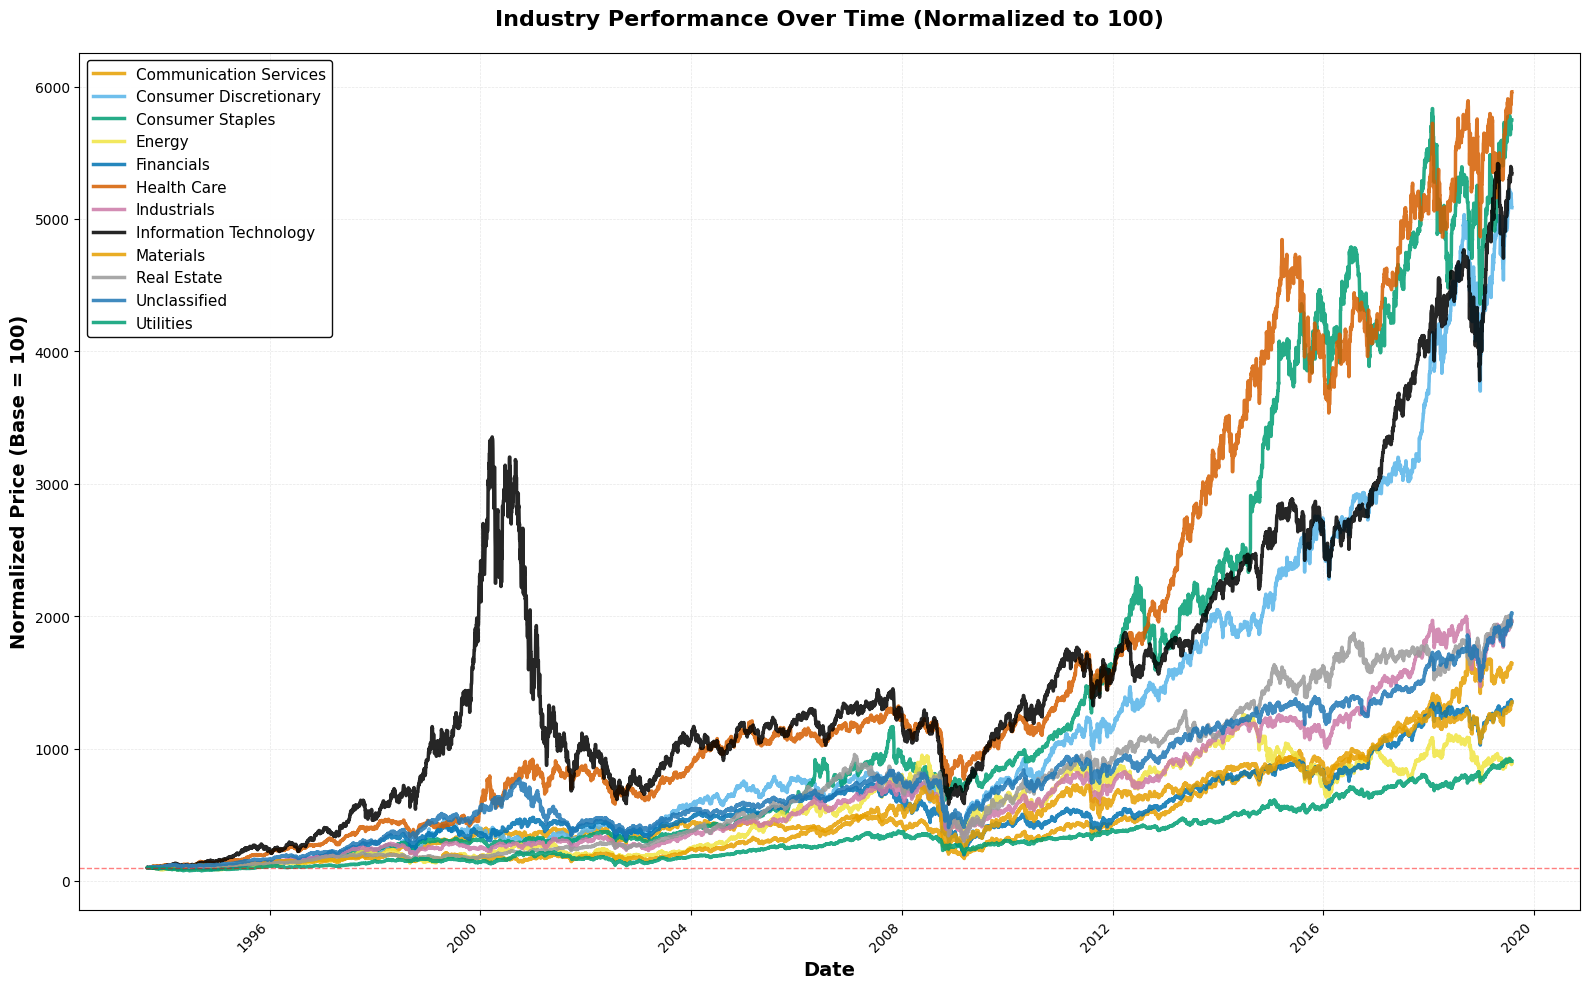


✓ Industry averages saved to 'industry_averages_normalized.csv'

  ANALYSIS COMPLETE!

Outputs created:
  1. industry_trends.png - Combined line graph
  2. industry_averages_normalized.csv - Time series data
  3. In-memory variables:
     - industry_data: Original prices by sector
     - industry_normalized: Normalized prices by sector
     - industry_averages: Average normalized price per sector
     - stats_df: Performance statistics


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

def create_industry_analysis(df_original, lookup_df):
    """
    Create industry-based dataframes and visualize trends over time.

    Parameters:
    - df_original: Your original DataFrame with Date index and Bloomberg columns
    - lookup_df: The classified_equities.csv output with sector mappings

    Returns:
    - industry_data: Dictionary of DataFrames, one per industry
    - industry_averages: DataFrame with average prices per industry over time
    """

    print("="*60)
    print("  CREATING INDUSTRY-BASED ANALYSIS")
    print("="*60)

    # Filter only resolved equities
    resolved = lookup_df[lookup_df['ticker'] != 'UNRESOLVED'].copy()
    print(f"\nWorking with {len(resolved)} resolved equities across {resolved['sector'].nunique()} sectors")

    # Create mapping: bloomberg_col -> sector
    col_to_sector = dict(zip(resolved['bloomberg_col'], resolved['sector']))

    # Initialize dictionary to store industry dataframes
    industry_data = {}
    industry_normalized = {}

    # Group columns by sector
    for sector in sorted(resolved['sector'].unique()):
        # Get all columns for this sector
        sector_cols = resolved[resolved['sector'] == sector]['bloomberg_col'].tolist()

        # Extract data for this sector
        sector_df = df_original[sector_cols].copy()

        # Store original data
        industry_data[sector] = sector_df

        # Normalize each column (standardize to base 100 at first date)
        # This allows fair comparison across different price ranges
        normalized_df = sector_df.copy()
        for col in sector_df.columns:
            first_valid = sector_df[col].first_valid_index()
            if first_valid is not None:
                base_value = sector_df.loc[first_valid, col]
                if base_value != 0 and not np.isnan(base_value):
                    normalized_df[col] = (sector_df[col] / base_value) * 100

        industry_normalized[sector] = normalized_df

        print(f"  {sector:<35} {len(sector_cols):>3} equities")

    print("\n" + "="*60)
    print("  CALCULATING INDUSTRY AVERAGES")
    print("="*60)

    # Calculate average normalized price for each industry over time
    industry_averages = pd.DataFrame(index=df_original.index)

    for sector, norm_df in industry_normalized.items():
        # Calculate mean across all equities in this sector for each date
        # Use nanmean to ignore NaN values
        industry_averages[sector] = norm_df.mean(axis=1)

    print(f"\nCreated time series from {industry_averages.index.min()} to {industry_averages.index.max()}")
    print(f"Total trading days: {len(industry_averages)}")

    return industry_data, industry_normalized, industry_averages


def plot_industry_trends(industry_averages, title="Industry Performance Over Time (Normalized to 100)"):
    """
    Plot all industries on a single line graph.

    Parameters:
    - industry_averages: DataFrame with Date index and industry columns
    """

    # Set up the plot with larger figure size
    fig, ax = plt.subplots(figsize=(16, 10))

    # Define colors for each sector (using a colorblind-friendly palette)
    colors = {
        'Communication Services': '#E69F00',    # Orange
        'Consumer Discretionary': '#56B4E9',    # Sky Blue
        'Consumer Staples': '#009E73',          # Bluish Green
        'Energy': '#F0E442',                     # Yellow
        'Financials': '#0072B2',                 # Blue
        'Health Care': '#D55E00',                # Vermillion
        'Industrials': '#CC79A7',                # Reddish Purple
        'Information Technology': '#000000',     # Black
        'Materials': '#E69F00',                  # Orange (lighter)
        'Real Estate': '#999999',                # Gray
        'Utilities': '#009E73'                   # Green (darker)
    }

    # Plot each industry
    for sector in industry_averages.columns:
        ax.plot(
            industry_averages.index,
            industry_averages[sector],
            label=sector,
            linewidth=2.5,
            color=colors.get(sector, None),
            alpha=0.85
        )

    # Formatting
    ax.set_xlabel('Date', fontsize=14, fontweight='bold')
    ax.set_ylabel('Normalized Price (Base = 100)', fontsize=14, fontweight='bold')
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)

    # Grid
    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    ax.set_axisbelow(True)

    # Legend
    ax.legend(
        loc='upper left',
        fontsize=11,
        framealpha=0.95,
        edgecolor='black',
        ncol=1
    )

    # Add horizontal reference line at 100
    ax.axhline(y=100, color='red', linestyle='--', linewidth=1, alpha=0.5, label='Base (100)')

    # Rotate x-axis labels
    plt.xticks(rotation=45, ha='right')

    # Tight layout
    plt.tight_layout()

    # Save the figure
    plt.savefig('industry_trends.png', dpi=300, bbox_inches='tight')
    print("\n✓ Plot saved as 'industry_trends.png'")

    plt.show()

    return fig, ax


def get_industry_statistics(industry_averages):
    """
    Calculate and display statistics for each industry.
    """
    print("\n" + "="*80)
    print("  INDUSTRY PERFORMANCE STATISTICS")
    print("="*80)
    print(f"\n{'Industry':<35} {'Start':<8} {'End':<8} {'Growth %':<12} {'Volatility':<12}")
    print("-"*80)

    stats = []
    for sector in industry_averages.columns:
        series = industry_averages[sector].dropna()
        if len(series) > 0:
            start_val = series.iloc[0]
            end_val = series.iloc[-1]
            growth_pct = ((end_val - start_val) / start_val) * 100
            volatility = series.std()

            stats.append({
                'Industry': sector,
                'Start': start_val,
                'End': end_val,
                'Growth %': growth_pct,
                'Volatility': volatility
            })

            print(f"{sector:<35} {start_val:>7.1f} {end_val:>7.1f} {growth_pct:>11.1f}% {volatility:>11.2f}")

    print("="*80)

    # Convert to DataFrame for further analysis
    stats_df = pd.DataFrame(stats)

    # Rank by growth
    print("\n" + "="*60)
    print("  TOP PERFORMERS (by Growth %)")
    print("="*60)
    top_performers = stats_df.nlargest(5, 'Growth %')[['Industry', 'Growth %']]
    for idx, row in top_performers.iterrows():
        print(f"  {row['Industry']:<40} {row['Growth %']:>8.1f}%")

    return stats_df


def plot_industry_trends_separate(industry_averages):
    """
    Create separate subplots for each industry (alternative visualization).
    """
    n_industries = len(industry_averages.columns)
    n_cols = 3
    n_rows = (n_industries + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4*n_rows))
    axes = axes.flatten()

    for idx, sector in enumerate(industry_averages.columns):
        ax = axes[idx]
        ax.plot(industry_averages.index, industry_averages[sector], linewidth=2)
        ax.set_title(sector, fontweight='bold', fontsize=12)
        ax.grid(True, alpha=0.3)
        ax.axhline(y=100, color='red', linestyle='--', linewidth=1, alpha=0.5)
        ax.set_ylabel('Normalized Price')

        # Rotate x-axis labels
        for label in ax.get_xticklabels():
            label.set_rotation(45)
            label.set_ha('right')

    # Hide extra subplots
    for idx in range(n_industries, len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    plt.savefig('industry_trends_separate.png', dpi=300, bbox_inches='tight')
    print("✓ Separate plots saved as 'industry_trends_separate.png'")
    plt.show()

    return fig, axes


# ═══════════════════════════════════════════════════════════════
# MAIN EXECUTION
# ═══════════════════════════════════════════════════════════════

# Step 1: Create industry analysis
industry_data, industry_normalized, industry_averages = create_industry_analysis(df, lookup_df)

# Step 2: Get statistics
stats_df = get_industry_statistics(industry_averages)

# Step 3: Plot all industries together
fig, ax = plot_industry_trends(industry_averages)

# Optional Step 4: Plot each industry separately
# Uncomment the line below if you want individual plots too
# plot_industry_trends_separate(industry_averages)

# Step 5: Save the industry averages data
industry_averages.to_csv('industry_averages_normalized.csv')
print("\n✓ Industry averages saved to 'industry_averages_normalized.csv'")

print("\n" + "="*60)
print("  ANALYSIS COMPLETE!")
print("="*60)
print(f"\nOutputs created:")
print(f"  1. industry_trends.png - Combined line graph")
print(f"  2. industry_averages_normalized.csv - Time series data")
print(f"  3. In-memory variables:")
print(f"     - industry_data: Original prices by sector")
print(f"     - industry_normalized: Normalized prices by sector")
print(f"     - industry_averages: Average normalized price per sector")
print(f"     - stats_df: Performance statistics")

###Data Visualisation:
1. General Trend: Equities from all industries have shown positive growth over 16 years.
2. Industry-specific Trends:

     1. IT Equities:
        * Rocketed around the year 2000, mainly due to the euphoria around the Internet and technology, high capital availability and easy IPOs, media and investor hype.
        * Bubble burst during March 2000, due to the failure of companies to deliver profit, increase of interest rates, panic selling by big-tech companies and capital drying up.


      2. All equities

          *   Global financial crisis.










#Industry Correlations

               INDUSTRY CORRELATION ANALYSIS              
  CALCULATING INDUSTRY CORRELATIONS

Calculated correlations using 9459 data points
Date range: 1993-09-07 00:00:00 to 2013-01-01 00:00:00

✓ Correlation heatmap saved as 'industry_correlation_heatmap.png'


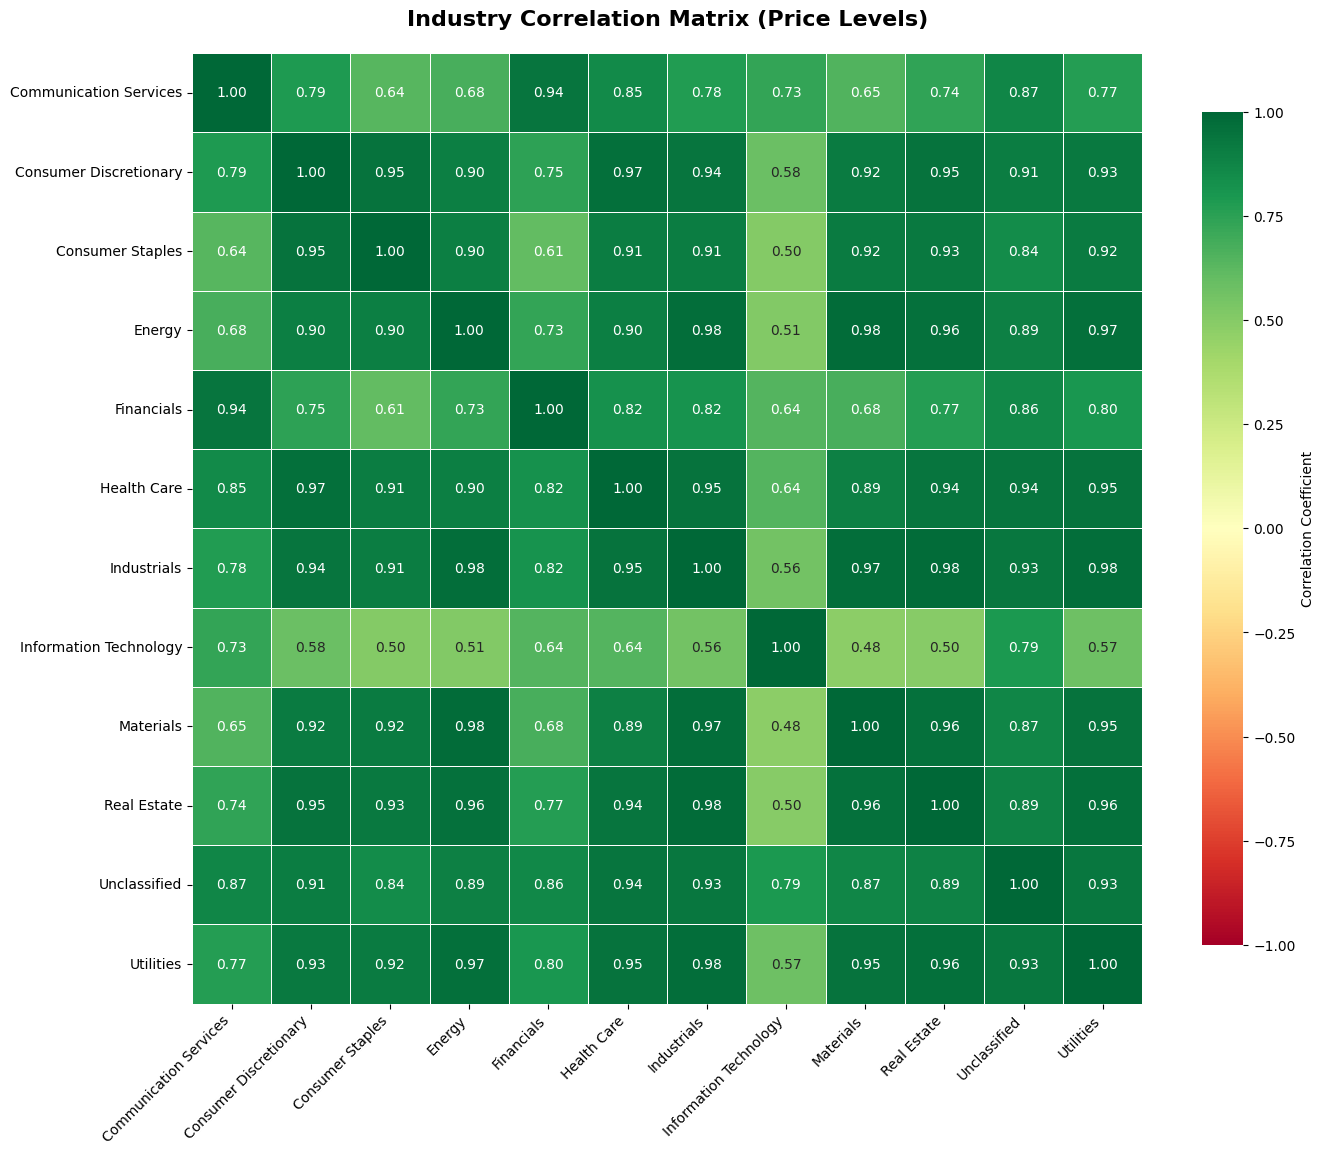

✓ Comparison heatmap saved as 'industry_correlation_comparison.png'


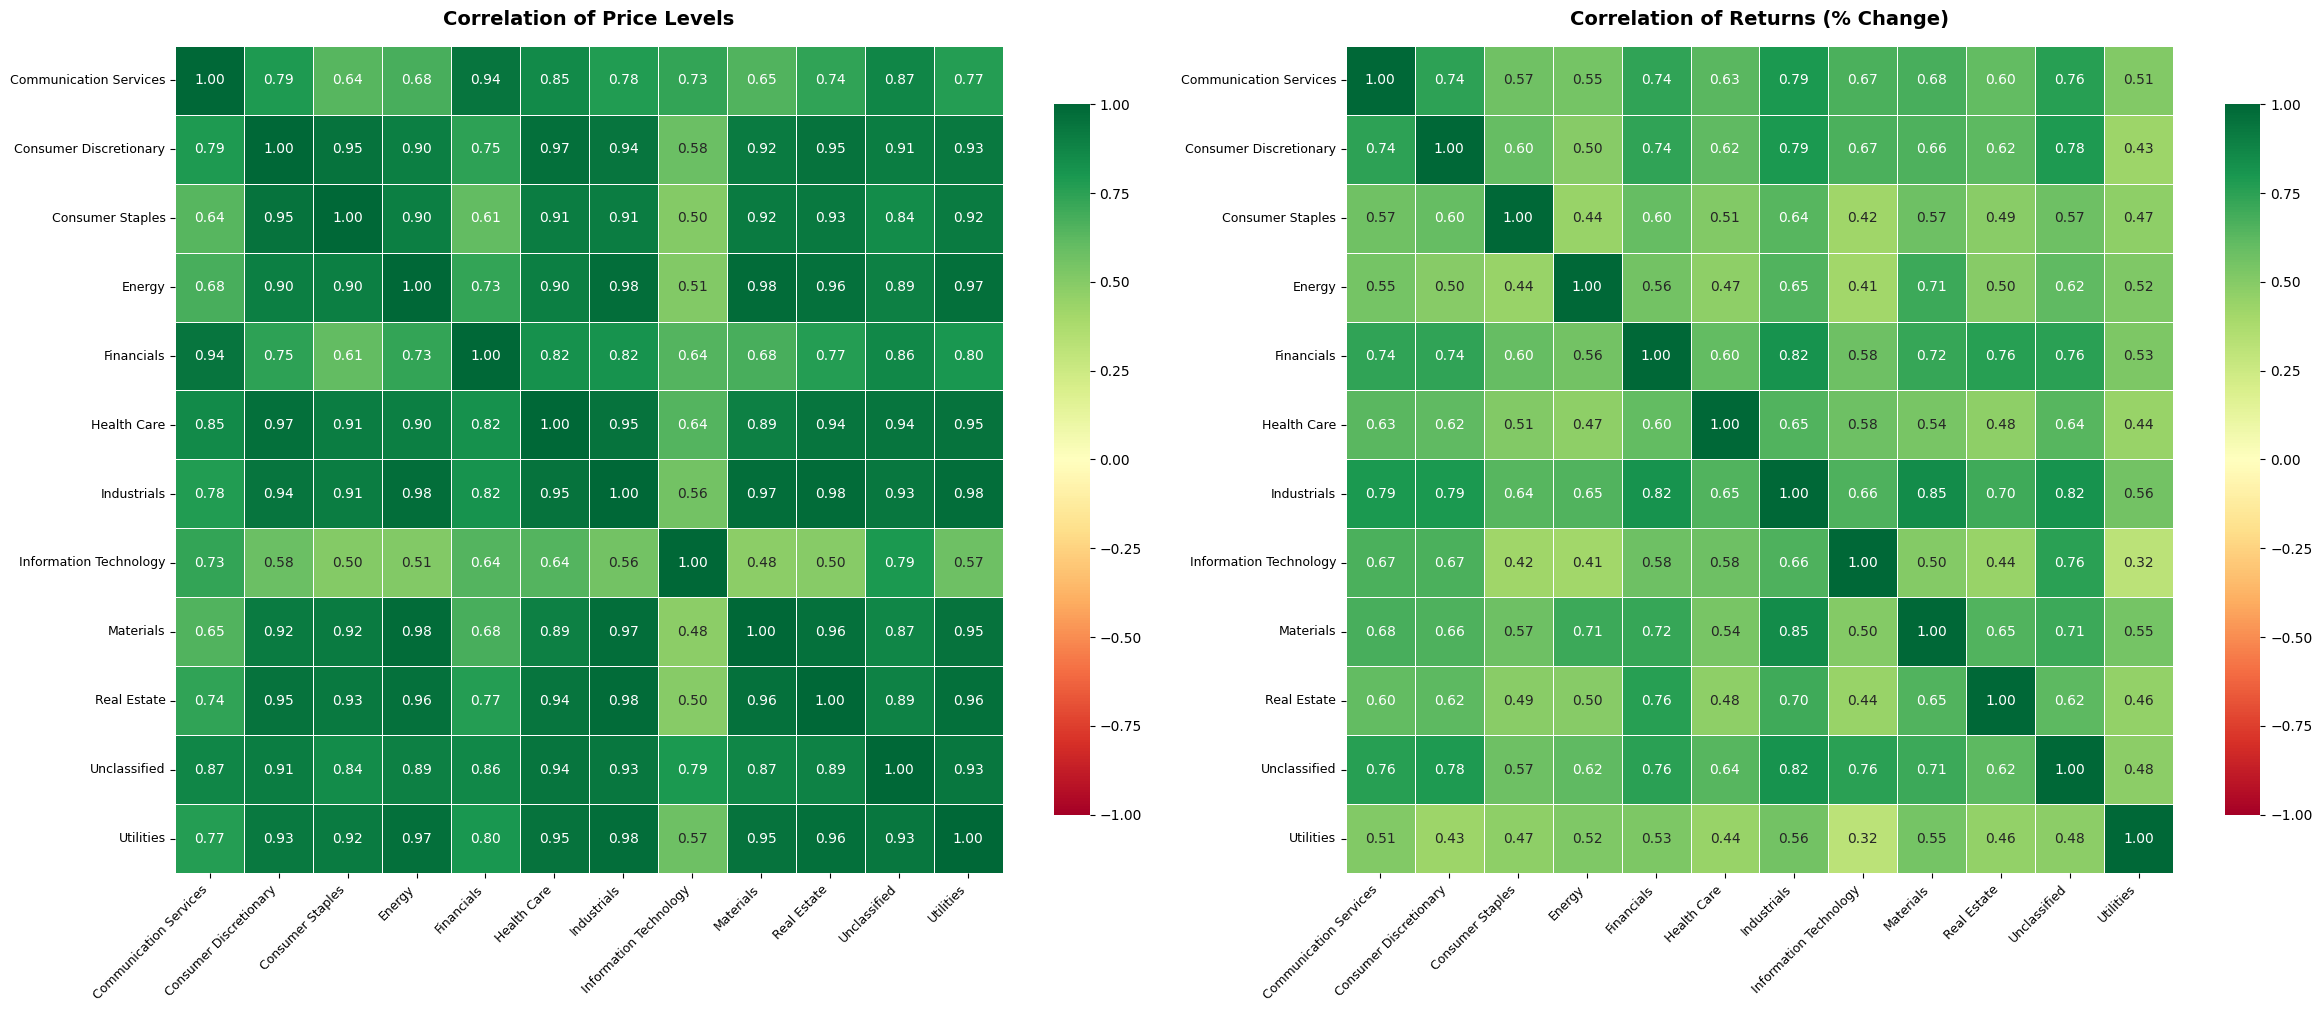


  CORRELATION INSIGHTS

┌─ MOST POSITIVELY CORRELATED INDUSTRIES (Price Levels) ─────────┐
Industry 1                     Industry 2                      Correlation
──────────────────────────────────────────────────────────────────────────
Energy                         Materials                            0.984
Industrials                    Real Estate                          0.979
Energy                         Industrials                          0.976
Industrials                    Utilities                            0.976
Industrials                    Materials                            0.971
Energy                         Utilities                            0.968
Consumer Discretionary         Health Care                          0.966
Real Estate                    Utilities                            0.964
Materials                      Real Estate                          0.960
Energy                         Real Estate                          0.959
└─────────────────

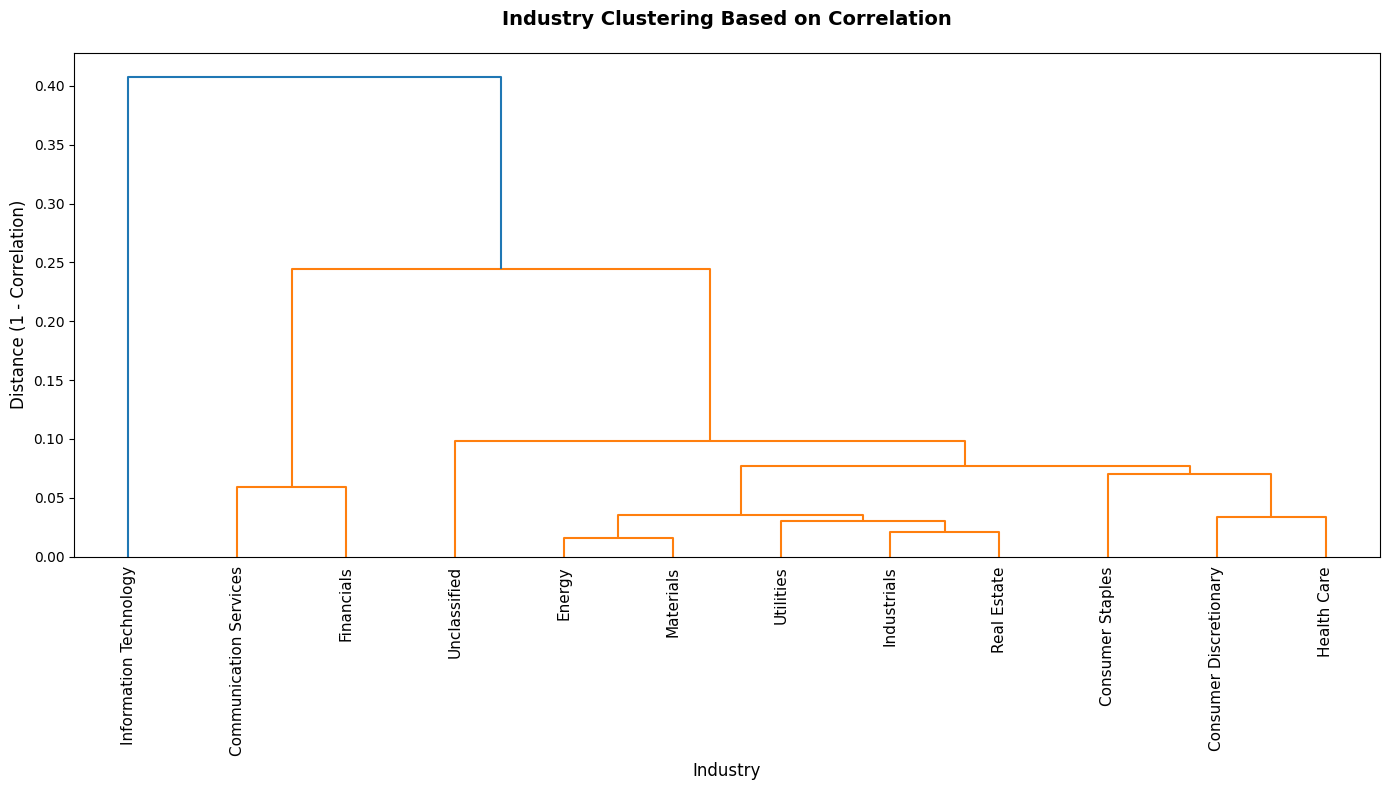

'\nprint("\n" + "="*60)\nprint("  ALL CORRELATION ANALYSES COMPLETE!")\nprint("="*60)\nprint("\nFiles created:")\nprint("  1. industry_correlation_heatmap.png")\nprint("  2. industry_correlation_comparison.png")\nprint("  3. industry_clustering.png")\nprint("  4. industry_correlation_matrix.csv")\nprint("  5. industry_returns_correlation_matrix.csv")\nprint("  6. industry_correlation_pairs.csv")\nprint("\nVariables created:")\nprint("  - correlation_matrix: Price level correlations")\nprint("  - returns_correlation: Returns correlations")\nprint("  - corr_pairs: All pairwise correlations")\nprint("  - avg_corr: Average correlation per industry")\nprint("="*60 + "\n")\n'

In [ ]:

def calculate_industry_correlations(industry_averages,start_date, end_date):
    """
    Calculate correlation matrix between industries.

    Parameters:
    - industry_averages: DataFrame with Date index and industry columns
    - start_date: Start date for analysis
    - end_date: End date for analysis

    Returns:
    - correlation_matrix: DataFrame with correlation coefficients
    - returns_correlation: DataFrame with correlation based on returns (not levels)
    """

    print("="*60)
    print("  CALCULATING INDUSTRY CORRELATIONS")
    print("="*60)

    filtered_industry_averages = industry_averages.loc[start_date:end_date]

    # Method 1: Correlation of price levels
    correlation_matrix = filtered_industry_averages.corr()

    # Method 2: Correlation of returns (more meaningful for financial analysis)
    # Calculate daily/periodic returns
    returns = filtered_industry_averages.pct_change().dropna()
    returns_correlation = returns.corr()

    print(f"\nCalculated correlations using {len(industry_averages)} data points")
    print(f"Date range: {filtered_industry_averages.index.min()} to {filtered_industry_averages.index.max()}")

    return correlation_matrix, returns_correlation, returns


def plot_correlation_heatmap(correlation_matrix, title="Industry Correlation Matrix",
                             filename="industry_correlation_heatmap.png"):
    """
    Create a beautiful heatmap of industry correlations.
    """

    fig, ax = plt.subplots(figsize=(14, 12))

    # Create heatmap
    sns.heatmap(
        correlation_matrix,
        annot=True,           # Show correlation values
        fmt='.2f',            # 2 decimal places
        cmap='RdYlGn',        # Red (negative) -> Yellow (neutral) -> Green (positive)
        center=0,             # Center colormap at 0
        square=True,          # Square cells
        linewidths=0.5,       # Lines between cells
        cbar_kws={
            "shrink": 0.8,
            "label": "Correlation Coefficient"
        },
        vmin=-1,              # Correlation ranges from -1 to 1
        vmax=1,
        ax=ax
    )

    # Formatting
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)

    # Rotate labels
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(rotation=0, fontsize=10)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"\n✓ Correlation heatmap saved as '{filename}'")
    plt.show()

    return fig, ax


def plot_correlation_heatmap_advanced(correlation_matrix, returns_correlation):
    """
    Create side-by-side comparison of price correlation vs returns correlation.
    """

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(24, 10))

    # Plot 1: Price levels correlation
    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt='.2f',
        cmap='RdYlGn',
        center=0,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8},
        vmin=-1,
        vmax=1,
        ax=ax1
    )
    ax1.set_title('Correlation of Price Levels', fontsize=14, fontweight='bold', pad=15)
    ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right', fontsize=9)
    ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0, fontsize=9)

    # Plot 2: Returns correlation
    sns.heatmap(
        returns_correlation,
        annot=True,
        fmt='.2f',
        cmap='RdYlGn',
        center=0,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8},
        vmin=-1,
        vmax=1,
        ax=ax2
    )
    ax2.set_title('Correlation of Returns (% Change)', fontsize=14, fontweight='bold', pad=15)
    ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right', fontsize=9)
    ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0, fontsize=9)

    plt.tight_layout()
    plt.savefig('industry_correlation_comparison.png', dpi=300, bbox_inches='tight')
    print("✓ Comparison heatmap saved as 'industry_correlation_comparison.png'")
    plt.show()

    return fig, (ax1, ax2)


def analyze_correlation_insights(correlation_matrix, returns_correlation):
    """
    Extract and display key insights from correlation analysis.
    """

    print("\n" + "="*80)
    print("  CORRELATION INSIGHTS")
    print("="*80)

    # Get upper triangle (avoid duplicates)
    mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)

    # Extract correlations
    correlations = []
    for i in range(len(correlation_matrix.columns)):
        for j in range(i+1, len(correlation_matrix.columns)):
            correlations.append({
                'Industry 1': correlation_matrix.columns[i],
                'Industry 2': correlation_matrix.columns[j],
                'Price Correlation': correlation_matrix.iloc[i, j],
                'Returns Correlation': returns_correlation.iloc[i, j]
            })

    corr_df = pd.DataFrame(correlations)

    # 1. HIGHEST CORRELATIONS
    print("\n┌─ MOST POSITIVELY CORRELATED INDUSTRIES (Price Levels) ─────────┐")
    print(f"{'Industry 1':<30} {'Industry 2':<30} {'Correlation':>12}")
    print("─"*74)
    top_corr = corr_df.nlargest(10, 'Price Correlation')
    for _, row in top_corr.iterrows():
        print(f"{row['Industry 1']:<30} {row['Industry 2']:<30} {row['Price Correlation']:>11.3f}")
    print("└" + "─"*73 + "┘")

    # 2. LOWEST CORRELATIONS (most diversified)
    print("\n┌─ LEAST CORRELATED INDUSTRIES (Best for Diversification) ───────┐")
    print(f"{'Industry 1':<30} {'Industry 2':<30} {'Correlation':>12}")
    print("─"*74)
    bottom_corr = corr_df.nsmallest(10, 'Price Correlation')
    for _, row in bottom_corr.iterrows():
        print(f"{row['Industry 1']:<30} {row['Industry 2']:<30} {row['Price Correlation']:>11.3f}")
    print("└" + "─"*73 + "┘")

    # 3. RETURNS CORRELATION ANALYSIS
    print("\n┌─ MOST POSITIVELY CORRELATED (Returns) ─────────────────────────┐")
    print(f"{'Industry 1':<30} {'Industry 2':<30} {'Correlation':>12}")
    print("─"*74)
    top_ret_corr = corr_df.nlargest(10, 'Returns Correlation')
    for _, row in top_ret_corr.iterrows():
        print(f"{row['Industry 1']:<30} {row['Industry 2']:<30} {row['Returns Correlation']:>11.3f}")
    print("└" + "─"*73 + "┘")

    # 4. AVERAGE CORRELATION PER INDUSTRY
    print("\n┌─ AVERAGE CORRELATION WITH OTHER INDUSTRIES ─────────────────────┐")
    print(f"{'Industry':<40} {'Avg Price Corr':>15} {'Avg Return Corr':>15}")
    print("─"*72)

    avg_correlations = []
    for industry in correlation_matrix.columns:
        # Get correlations with all other industries (exclude self)
        price_corrs = correlation_matrix[industry].drop(industry)
        return_corrs = returns_correlation[industry].drop(industry)

        avg_correlations.append({
            'Industry': industry,
            'Avg Price Correlation': price_corrs.mean(),
            'Avg Return Correlation': return_corrs.mean()
        })

    avg_corr_df = pd.DataFrame(avg_correlations).sort_values('Avg Price Correlation', ascending=False)

    for _, row in avg_corr_df.iterrows():
        print(f"{row['Industry']:<40} {row['Avg Price Correlation']:>14.3f} {row['Avg Return Correlation']:>14.3f}")
    print("└" + "─"*71 + "┘")

    # 5. SUMMARY STATISTICS
    print("\n┌─ SUMMARY STATISTICS ────────────────────────────────────────────┐")
    print(f"  Overall average correlation (prices):  {corr_df['Price Correlation'].mean():>6.3f}")
    print(f"  Overall average correlation (returns): {corr_df['Returns Correlation'].mean():>6.3f}")
    print(f"  Highest correlation:                   {corr_df['Price Correlation'].max():>6.3f}")
    print(f"  Lowest correlation:                    {corr_df['Price Correlation'].min():>6.3f}")
    print(f"  Standard deviation:                    {corr_df['Price Correlation'].std():>6.3f}")
    print("└" + "─"*67 + "┘")

    return corr_df, avg_corr_df



def plot_correlation_clusters(correlation_matrix):
    """
    Use hierarchical clustering to group similar industries.
    """
    from scipy.cluster.hierarchy import dendrogram, linkage
    from scipy.spatial.distance import squareform

    # Convert correlation to distance
    distance_matrix = 1 - correlation_matrix

    # Perform hierarchical clustering
    condensed_dist = squareform(distance_matrix)
    linkage_matrix = linkage(condensed_dist, method='average')

    # Plot dendrogram
    fig, ax = plt.subplots(figsize=(14, 8))

    dendrogram(
        linkage_matrix,
        labels=correlation_matrix.columns,
        leaf_rotation=90,
        leaf_font_size=11,
        ax=ax
    )

    ax.set_title('Industry Clustering Based on Correlation',
                 fontsize=14, fontweight='bold', pad=20)
    ax.set_ylabel('Distance (1 - Correlation)', fontsize=12)
    ax.set_xlabel('Industry', fontsize=12)

    plt.tight_layout()
    plt.savefig('industry_clustering.png', dpi=300, bbox_inches='tight')
    print("✓ Clustering dendrogram saved as 'industry_clustering.png'")
    plt.show()

    return fig, ax


# ═══════════════════════════════════════════════════════════════
# MAIN EXECUTION
# ═══════════════════════════════════════════════════════════════


print("  INDUSTRY CORRELATION ANALYSIS".center(58))

# Step 1: Calculate correlations
correlation_matrix, returns_correlation, returns = calculate_industry_correlations(industry_averages,start_date='1993-09-07', end_date='2013-01-01')

# Step 2: Create basic heatmap
plot_correlation_heatmap(
    correlation_matrix,
    title="Industry Correlation Matrix (Price Levels)",
    filename="industry_correlation_heatmap.png"
)

# Step 3: Create comparison heatmap (price vs returns)
plot_correlation_heatmap_advanced(correlation_matrix, returns_correlation)

# Step 4: Analyze and display insights
corr_pairs, avg_corr = analyze_correlation_insights(correlation_matrix, returns_correlation)

# Step 5: Create clustering dendrogram
plot_correlation_clusters(correlation_matrix)

# Step 6: Save correlation data to CSV
correlation_matrix.to_csv('industry_correlation_matrix.csv')
returns_correlation.to_csv('industry_returns_correlation_matrix.csv')
corr_pairs.to_csv('industry_correlation_pairs.csv', index=False)

"""
print("\n" + "="*60)
print("  ALL CORRELATION ANALYSES COMPLETE!")
print("="*60)
print("\nFiles created:")
print("  1. industry_correlation_heatmap.png")
print("  2. industry_correlation_comparison.png")
print("  3. industry_clustering.png")
print("  4. industry_correlation_matrix.csv")
print("  5. industry_returns_correlation_matrix.csv")
print("  6. industry_correlation_pairs.csv")
print("\nVariables created:")
print("  - correlation_matrix: Price level correlations")
print("  - returns_correlation: Returns correlations")
print("  - corr_pairs: All pairwise correlations")
print("  - avg_corr: Average correlation per industry")
print("="*60 + "\n")
"""

#Finding optimum number of stocks in a portfolio
###by using annual volatility threshold of 25% and 35%. Ended up with 35% to maximise return while keeping portfolio volatility under acceptable limit.


Calculating stock metrics...
Calculated metrics for 396 stocks across 12 sectors

Creating scatterplot...


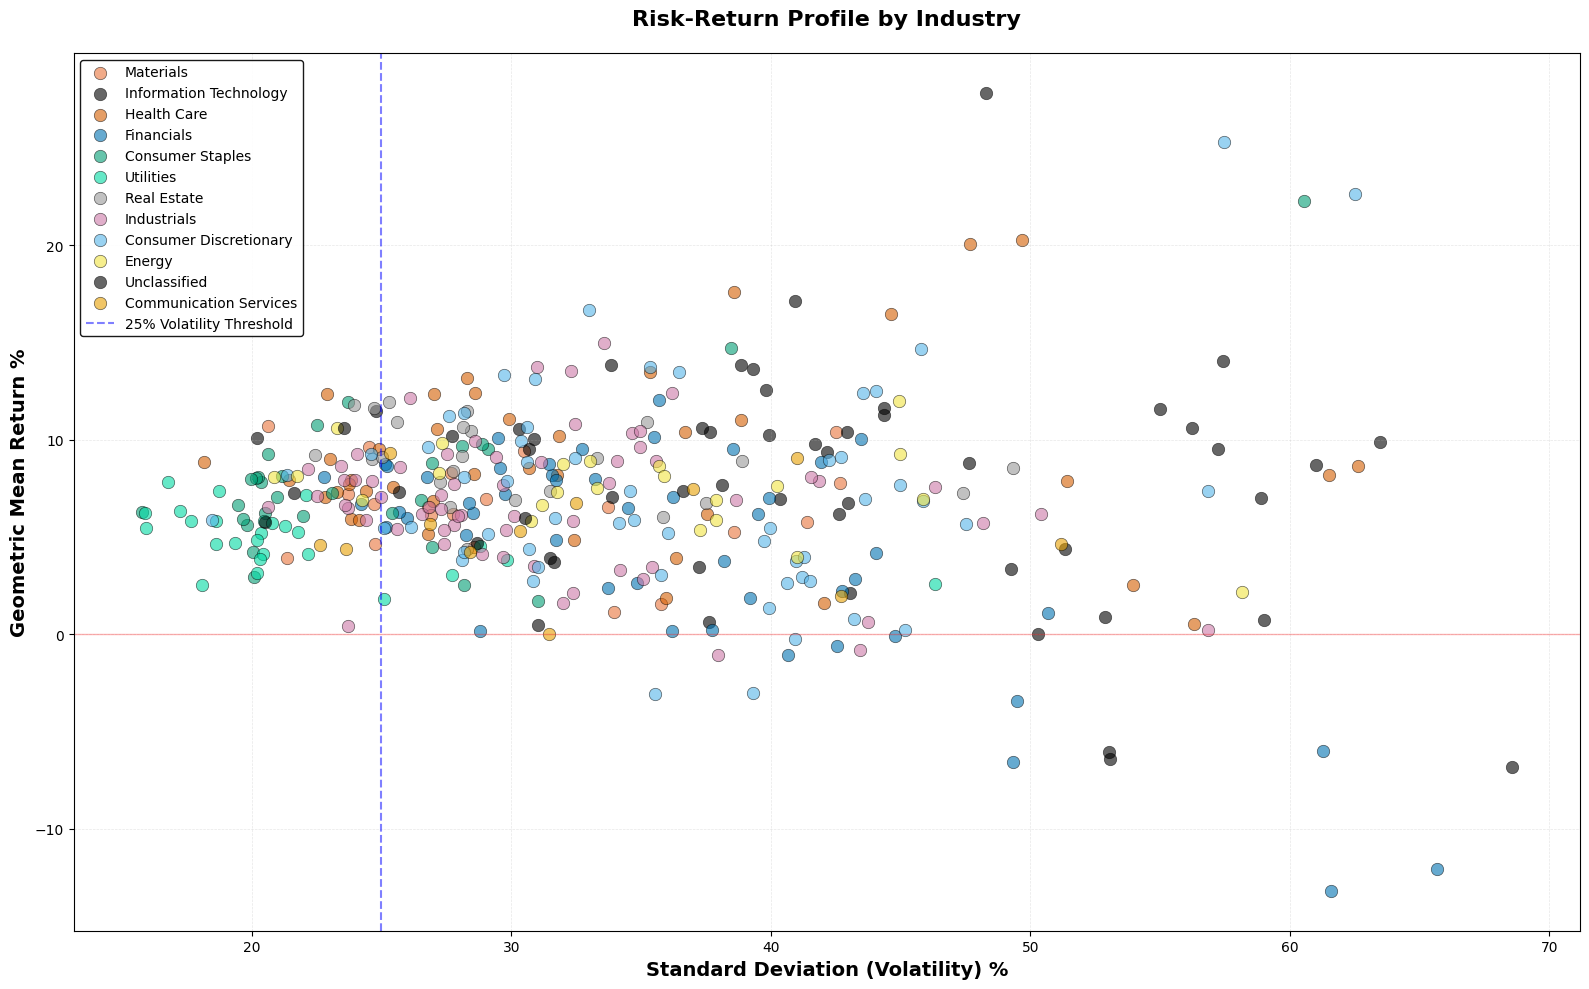


Finding top stocks per industry (volatility <  25 %)...

TOP 10 STOCKS PER INDUSTRY (Volatility <  25 %)

Communication Services (2 stocks)
----------------------------------------------------------------------------------------------------
Rank   Ticker       Name                                Geo Mean %      Std Dev %   
----------------------------------------------------------------------------------------------------
1      VZ           Verizon Communications Inc.                  4.60       22.62
2      T            AT&T Inc.                                    4.37       23.63

Consumer Discretionary (3 stocks)
----------------------------------------------------------------------------------------------------
Rank   Ticker       Name                                Geo Mean %      Std Dev %   
----------------------------------------------------------------------------------------------------
1      VFC          V.F. Corporation                             9.27       24.59
2   

'\n# Save results\nmetrics_df.to_csv(\'stock_risk_return_metrics.csv\', index=False)\n\n# Save top stocks to CSV\nall_top_stocks = pd.concat([df.assign(Sector=sector) for sector, df in top_stocks_dict.items()])\nall_top_stocks.to_csv(\'top_stocks_low_volatility.csv\', index=False)\n\nprint("\nFiles saved:")\nprint("  - risk_return_scatterplot.png")\nprint("  - stock_risk_return_metrics.csv")\nprint("  - top_stocks_low_volatility.csv")\n'

In [ ]:

def calculate_stock_metrics(df_original, lookup_df):
    """
    Calculate geometric mean and standard deviation for each stock.

    Parameters:
    - df_original: DataFrame with Date index and stock columns
    - lookup_df: DataFrame with sector classifications

    Returns:
    - metrics_df: DataFrame with stock metrics
    """

    # Filter only resolved stocks
    resolved = lookup_df[lookup_df['ticker'] != 'UNRESOLVED'].copy()

    metrics = []

    for _, row in resolved.iterrows():
        bloomberg_col = row['bloomberg_col']
        sector = row['sector']
        ticker = row['ticker']

        if bloomberg_col in df_original.columns:
            prices = df_original[bloomberg_col].dropna()

            if len(prices) > 1:
                # Calculate returns
                returns = prices.pct_change().dropna()

                # Geometric mean of returns (annualized)
                # Add 1 to returns, take geometric mean, subtract 1, annualize
                if len(returns) > 0 and (returns + 1).prod() > 0:
                    geometric_mean = (returns + 1).prod() ** (252 / len(returns)) - 1
                    geometric_mean_pct = geometric_mean * 100  # Convert to percentage
                else:
                    geometric_mean_pct = np.nan

                # Standard deviation of returns (annualized)
                std_dev = returns.std() * np.sqrt(252) * 100  # Convert to percentage

                metrics.append({
                    'bloomberg_col': bloomberg_col,
                    'ticker': ticker,
                    'sector': sector,
                    'name': row['name'],
                    'geometric_mean': geometric_mean_pct,
                    'std_dev': std_dev
                })

    metrics_df = pd.DataFrame(metrics)

    # Remove any rows with NaN values
    metrics_df = metrics_df.dropna(subset=['geometric_mean', 'std_dev'])

    return metrics_df


def plot_risk_return_scatterplot(metrics_df):
    """
    Create scatterplot with standard deviation (X) vs geometric mean (Y).
    """

    fig, ax = plt.subplots(figsize=(16, 10))

    # Define colors for each sector
    sector_colors = {
        'Communication Services': '#E69F00',
        'Consumer Discretionary': '#56B4E9',
        'Consumer Staples': '#009E73',
        'Energy': '#F0E442',
        'Financials': '#0072B2',
        'Health Care': '#D55E00',
        'Industrials': '#CC79A7',
        'Information Technology': '#000000',
        'Materials': '#E8743B',
        'Real Estate': '#999999',
        'Utilities': '#00D9A3'
    }

    # Plot each sector
    for sector in metrics_df['sector'].unique():
        sector_data = metrics_df[metrics_df['sector'] == sector]

        ax.scatter(
            sector_data['std_dev'],
            sector_data['geometric_mean'],
            c=sector_colors.get(sector, '#000000'),
            label=sector,
            alpha=0.6,
            s=80,
            edgecolors='black',
            linewidth=0.5
        )

    ax.set_xlabel('Standard Deviation (Volatility) %', fontsize=14, fontweight='bold')
    ax.set_ylabel('Geometric Mean Return %', fontsize=14, fontweight='bold')
    ax.set_title('Risk-Return Profile by Industry', fontsize=16, fontweight='bold', pad=20)

    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    ax.axhline(y=0, color='red', linestyle='-', linewidth=1, alpha=0.3)
    ax.axvline(x=25, color='blue', linestyle='--', linewidth=1.5, alpha=0.5, label='25% Volatility Threshold')

    ax.legend(loc='best', fontsize=10, framealpha=0.9, edgecolor='black')

    plt.tight_layout()
    plt.savefig('risk_return_scatterplot.png', dpi=300, bbox_inches='tight')
    plt.show()

    return fig, ax


def get_top_stocks_by_industry(metrics_df, volatility_threshold, top_n=10):
    """
    Get top N stocks from each industry with volatility less than threshold.
    Ranked by geometric mean (highest return).
    """

    # Filter by volatility threshold
    low_vol = metrics_df[metrics_df['std_dev'] < volatility_threshold].copy()

    results = {}

    for sector in sorted(low_vol['sector'].unique()):
        sector_stocks = low_vol[low_vol['sector'] == sector].copy()

        # Sort by geometric mean (descending)
        sector_stocks = sector_stocks.sort_values('geometric_mean', ascending=False)

        # Take top N
        top_stocks = sector_stocks.head(top_n)

        results[sector] = top_stocks

    return results


def display_top_stocks(top_stocks_dict,volatility_threshold):
    """
    Display the top stocks for each industry.
    """

    print("\n" + "="*100)
    print("TOP 10 STOCKS PER INDUSTRY (Volatility < ",volatility_threshold,"%)")
    print("="*100)

    for sector in sorted(top_stocks_dict.keys()):
        stocks = top_stocks_dict[sector]

        if len(stocks) == 0:
            print(f"\n{sector}: No stocks with volatility < ",volatility_threshold,"%")
            continue

        print(f"\n{sector} ({len(stocks)} stocks)")
        print("-"*100)
        print(f"{'Rank':<6} {'Ticker':<12} {'Name':<35} {'Geo Mean %':<15} {'Std Dev %':<12}")
        print("-"*100)

        for rank, (_, row) in enumerate(stocks.iterrows(), 1):
            print(f"{rank:<6} {row['ticker']:<12} {row['name'][:34]:<35} {row['geometric_mean']:>13.2f} {row['std_dev']:>11.2f}")

    print("="*100)


def create_summary_statistics(metrics_df, top_stocks_dict):
    """
    Create summary statistics table.
    """

    summary = []

    for sector in sorted(metrics_df['sector'].unique()):
        sector_data = metrics_df[metrics_df['sector'] == sector]
        low_vol_data = sector_data[sector_data['std_dev'] < 15]

        # Safely get best stock and return
        if len(low_vol_data) > 0:
            best_stock_row = low_vol_data.nlargest(1, 'geometric_mean')
            best_stock = best_stock_row['ticker'].values[0]
            best_return = best_stock_row['geometric_mean'].values[0]
        else:
            best_stock = 'N/A'
            best_return = np.nan

        summary.append({
            'Sector': sector,
            'Total Stocks': len(sector_data),
            'Low Vol Stocks': len(low_vol_data),})


# Main execution
df_filtered = df.loc['1993-09-07':'2013-01-01']
volatility_threshold = 25
print("\nCalculating stock metrics...")
metrics_df = calculate_stock_metrics(df_filtered, lookup_df)

print(f"Calculated metrics for {len(metrics_df)} stocks across {metrics_df['sector'].nunique()} sectors")

print("\nCreating scatterplot...")
fig, ax = plot_risk_return_scatterplot(metrics_df)

print("\nFinding top stocks per industry (volatility < ",volatility_threshold,"%)...")
top_stocks_dict = get_top_stocks_by_industry(metrics_df, volatility_threshold, top_n=10)

display_top_stocks(top_stocks_dict,volatility_threshold)

summary_df = create_summary_statistics(metrics_df, top_stocks_dict)

"""
# Save results
metrics_df.to_csv('stock_risk_return_metrics.csv', index=False)

# Save top stocks to CSV
all_top_stocks = pd.concat([df.assign(Sector=sector) for sector, df in top_stocks_dict.items()])
all_top_stocks.to_csv('top_stocks_low_volatility.csv', index=False)

print("\nFiles saved:")
print("  - risk_return_scatterplot.png")
print("  - stock_risk_return_metrics.csv")
print("  - top_stocks_low_volatility.csv")
"""


Starting portfolio size optimization...

PORTFOLIO SIZE OPTIMIZATION
N Stocks     Portfolio Return %   Portfolio Volatility % Sharpe Ratio   
----------------------------------------------------------------------------------------------------
5                         13.34                16.13          0.827
10                        13.25                14.38          0.921
15                        12.63                14.05          0.899
20                        12.25                13.75          0.891
25                        11.91                13.23          0.900
30                        11.66                12.98          0.898
35                        11.42                12.93          0.884
40                        11.23                12.75          0.880
45                         8.74                13.63          0.641
50                         8.63                13.88          0.622


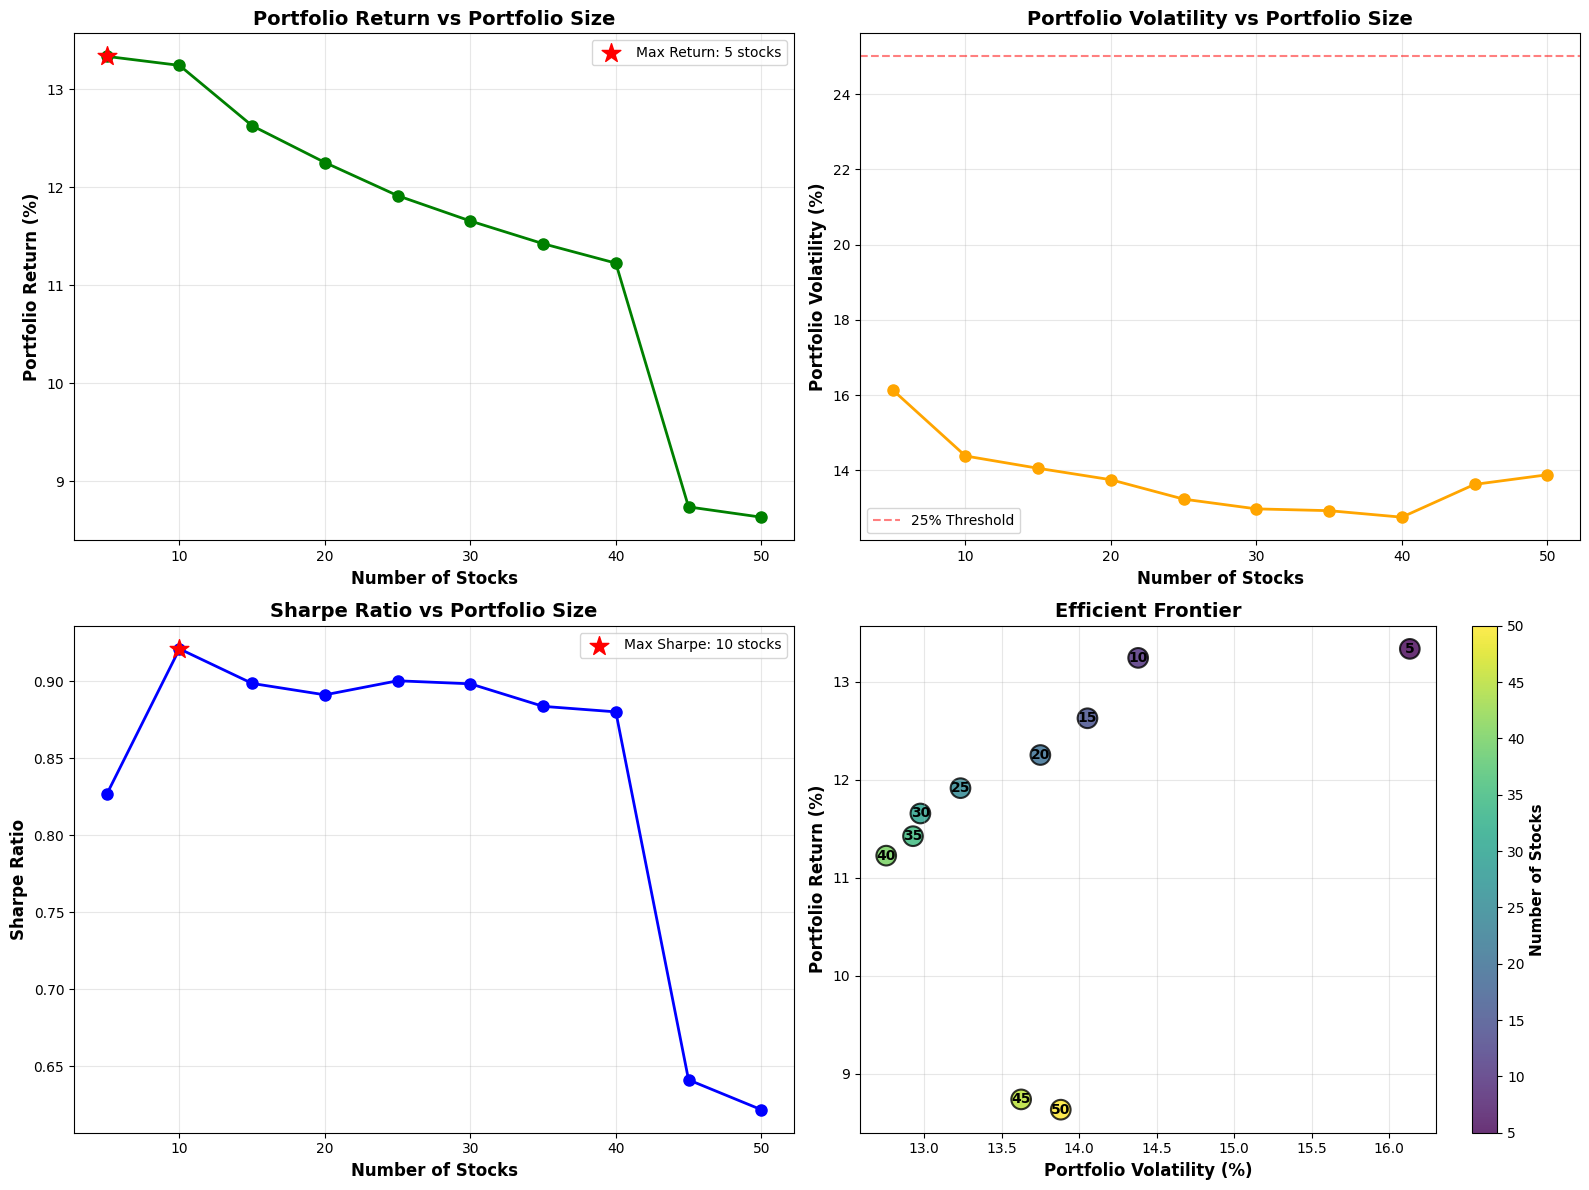


OPTIMAL PORTFOLIO RECOMMENDATIONS

1. MAXIMUM SHARPE RATIO (Best Risk-Adjusted Return):
   Optimal Number of Stocks: 10
   Portfolio Return: 13.25%
   Portfolio Volatility: 14.38%
   Sharpe Ratio: 0.921

2. MAXIMUM RETURN:
   Optimal Number of Stocks: 5
   Portfolio Return: 13.34%
   Portfolio Volatility: 16.13%
   Sharpe Ratio: 0.827

3. ELBOW METHOD (Diminishing Returns):
   Optimal Number of Stocks: 10
   Portfolio Return: 13.25%
   Portfolio Volatility: 14.38%
   Sharpe Ratio: 0.921

RECOMMENDATION: Use the portfolio with the MAXIMUM SHARPE RATIO
                (10 stocks)

OPTIMAL PORTFOLIO COMPOSITION
Rank   Ticker       Sector                         Name                                Geo Mean %      Std Dev %   
------------------------------------------------------------------------------------------------------------------------
1      DHR          Health Care                    Danaher Corporation                         12.38       22.90
2      MO           Consumer Stap

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

def select_top_stocks_by_return(metrics_df, n_stocks, volatility_threshold):
    """
    Select top N stocks with highest geometric mean and volatility < threshold.
    """
    # Filter by volatility
    eligible = metrics_df[metrics_df['std_dev'] < volatility_threshold].copy()

    # Sort by geometric mean (descending)
    eligible = eligible.sort_values('geometric_mean', ascending=False)

    # Select top N
    selected = eligible.head(n_stocks)

    return selected


def calculate_portfolio_metrics(selected_stocks, df_original):
    """
    Calculate portfolio return and volatility using equal weights.
    """
    # Get returns for selected stocks
    returns_list = []

    for _, stock in selected_stocks.iterrows():
        bloomberg_col = stock['bloomberg_col']
        if bloomberg_col in df_original.columns:
            prices = df_original[bloomberg_col].dropna()
            returns = prices.pct_change().dropna()
            returns_list.append(returns)

    # Align all returns to same dates
    returns_df = pd.DataFrame({i: ret for i, ret in enumerate(returns_list)})
    returns_df = returns_df.dropna()

    if len(returns_df) == 0:
        return np.nan, np.nan, np.nan

    # Equal weights
    n_stocks = len(returns_list)
    weights = np.array([1/n_stocks] * n_stocks)

    # Portfolio returns
    portfolio_returns = (returns_df * weights).sum(axis=1)

    # Annualized metrics
    portfolio_geo_mean = ((1 + portfolio_returns).prod() ** (252 / len(portfolio_returns)) - 1) * 100
    portfolio_std = portfolio_returns.std() * np.sqrt(252) * 100
    sharpe_ratio = portfolio_geo_mean / portfolio_std if portfolio_std > 0 else 0

    return portfolio_geo_mean, portfolio_std, sharpe_ratio


def optimize_portfolio_size(metrics_df, df_original, portfolio_sizes, volatility_threshold):
    """
    Test different portfolio sizes and find optimal number of stocks.
    """
    results = []

    print("\n" + "="*100)
    print("PORTFOLIO SIZE OPTIMIZATION")
    print("="*100)
    print(f"{'N Stocks':<12} {'Portfolio Return %':<20} {'Portfolio Volatility %':<22} {'Sharpe Ratio':<15}")
    print("-"*100)

    for n in portfolio_sizes:
        # Select top N stocks
        selected = select_top_stocks_by_return(metrics_df, n, volatility_threshold)

        if len(selected) < n:
            print(f"{n:<12} Not enough eligible stocks (only {len(selected)} available)")
            continue

        # Calculate portfolio metrics
        port_return, port_vol, sharpe = calculate_portfolio_metrics(selected, df_original)

        if pd.notna(port_return):
            results.append({
                'n_stocks': n,
                'portfolio_return': port_return,
                'portfolio_volatility': port_vol,
                'sharpe_ratio': sharpe,
                'selected_stocks': selected
            })

            print(f"{n:<12} {port_return:>18.2f} {port_vol:>20.2f} {sharpe:>14.3f}")

    print("="*100)

    results_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'selected_stocks'}
                               for r in results])

    return results, results_df


def plot_optimization_results(results_df):
    """
    Plot the results of portfolio size optimization.
    """
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Plot 1: Portfolio Return vs Number of Stocks
    ax1 = axes[0, 0]
    ax1.plot(results_df['n_stocks'], results_df['portfolio_return'],
             marker='o', linewidth=2, markersize=8, color='green')
    ax1.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Portfolio Return (%)', fontsize=12, fontweight='bold')
    ax1.set_title('Portfolio Return vs Portfolio Size', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)

    # Highlight maximum
    max_return_idx = results_df['portfolio_return'].idxmax()
    max_return_n = results_df.loc[max_return_idx, 'n_stocks']
    max_return_val = results_df.loc[max_return_idx, 'portfolio_return']
    ax1.scatter([max_return_n], [max_return_val], color='red', s=200, zorder=5,
                marker='*', label=f'Max Return: {max_return_n} stocks')
    ax1.legend()

    # Plot 2: Portfolio Volatility vs Number of Stocks
    ax2 = axes[0, 1]
    ax2.plot(results_df['n_stocks'], results_df['portfolio_volatility'],
             marker='o', linewidth=2, markersize=8, color='orange')
    ax2.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Portfolio Volatility (%)', fontsize=12, fontweight='bold')
    ax2.set_title('Portfolio Volatility vs Portfolio Size', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.axhline(y=25, color='red', linestyle='--', alpha=0.5, label='25% Threshold')
    ax2.legend()

    # Plot 3: Sharpe Ratio vs Number of Stocks
    ax3 = axes[1, 0]
    ax3.plot(results_df['n_stocks'], results_df['sharpe_ratio'],
             marker='o', linewidth=2, markersize=8, color='blue')
    ax3.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Sharpe Ratio', fontsize=12, fontweight='bold')
    ax3.set_title('Sharpe Ratio vs Portfolio Size', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3)

    # Highlight maximum
    max_sharpe_idx = results_df['sharpe_ratio'].idxmax()
    max_sharpe_n = results_df.loc[max_sharpe_idx, 'n_stocks']
    max_sharpe_val = results_df.loc[max_sharpe_idx, 'sharpe_ratio']
    ax3.scatter([max_sharpe_n], [max_sharpe_val], color='red', s=200, zorder=5,
                marker='*', label=f'Max Sharpe: {max_sharpe_n} stocks')
    ax3.legend()

    # Plot 4: Return vs Volatility (Efficient Frontier)
    ax4 = axes[1, 1]
    scatter = ax4.scatter(results_df['portfolio_volatility'], results_df['portfolio_return'],
                         c=results_df['n_stocks'], s=200, cmap='viridis',
                         edgecolors='black', linewidth=1.5, alpha=0.8)

    # Add labels for each point
    for _, row in results_df.iterrows():
        ax4.annotate(f"{int(row['n_stocks'])}",
                    (row['portfolio_volatility'], row['portfolio_return']),
                    fontsize=10, ha='center', va='center', fontweight='bold')

    ax4.set_xlabel('Portfolio Volatility (%)', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Portfolio Return (%)', fontsize=12, fontweight='bold')
    ax4.set_title('Efficient Frontier', fontsize=14, fontweight='bold')
    ax4.grid(True, alpha=0.3)

    cbar = plt.colorbar(scatter, ax=ax4)
    cbar.set_label('Number of Stocks', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.savefig('portfolio_size_optimization.png', dpi=300, bbox_inches='tight')
    plt.show()

    return fig, axes


def find_optimal_portfolio(results, results_df):
    """
    Determine the optimal portfolio size based on various criteria.
    """
    print("\n" + "="*100)
    print("OPTIMAL PORTFOLIO RECOMMENDATIONS")
    print("="*100)

    # Criterion 1: Maximum Sharpe Ratio
    max_sharpe_idx = results_df['sharpe_ratio'].idxmax()
    optimal_sharpe = results_df.loc[max_sharpe_idx]

    print(f"\n1. MAXIMUM SHARPE RATIO (Best Risk-Adjusted Return):")
    print(f"   Optimal Number of Stocks: {int(optimal_sharpe['n_stocks'])}")
    print(f"   Portfolio Return: {optimal_sharpe['portfolio_return']:.2f}%")
    print(f"   Portfolio Volatility: {optimal_sharpe['portfolio_volatility']:.2f}%")
    print(f"   Sharpe Ratio: {optimal_sharpe['sharpe_ratio']:.3f}")

    # Criterion 2: Maximum Return
    max_return_idx = results_df['portfolio_return'].idxmax()
    optimal_return = results_df.loc[max_return_idx]

    print(f"\n2. MAXIMUM RETURN:")
    print(f"   Optimal Number of Stocks: {int(optimal_return['n_stocks'])}")
    print(f"   Portfolio Return: {optimal_return['portfolio_return']:.2f}%")
    print(f"   Portfolio Volatility: {optimal_return['portfolio_volatility']:.2f}%")
    print(f"   Sharpe Ratio: {optimal_return['sharpe_ratio']:.3f}")

    # Criterion 3: Elbow method (marginal benefit analysis)
    results_df_sorted = results_df.sort_values('n_stocks')
    marginal_returns = results_df_sorted['portfolio_return'].diff()

    # Find where marginal benefit drops significantly
    if len(marginal_returns) > 2:
        avg_marginal = marginal_returns.mean()
        threshold = avg_marginal * 0.3  # Less than 30% of average marginal benefit

        elbow_candidates = results_df_sorted[marginal_returns < threshold]
        if len(elbow_candidates) > 0:
            elbow_idx = elbow_candidates.index[0] - 1
            if elbow_idx in results_df_sorted.index:
                optimal_elbow = results_df_sorted.loc[elbow_idx]

                print(f"\n3. ELBOW METHOD (Diminishing Returns):")
                print(f"   Optimal Number of Stocks: {int(optimal_elbow['n_stocks'])}")
                print(f"   Portfolio Return: {optimal_elbow['portfolio_return']:.2f}%")
                print(f"   Portfolio Volatility: {optimal_elbow['portfolio_volatility']:.2f}%")
                print(f"   Sharpe Ratio: {optimal_elbow['sharpe_ratio']:.3f}")

    print("\n" + "="*100)
    print("RECOMMENDATION: Use the portfolio with the MAXIMUM SHARPE RATIO")
    print(f"                ({int(optimal_sharpe['n_stocks'])} stocks)")
    print("="*100)

    # Return the optimal portfolio
    optimal_portfolio_idx = max_sharpe_idx
    optimal_stocks = results[optimal_portfolio_idx]['selected_stocks']

    return optimal_stocks, optimal_sharpe


def display_optimal_portfolio(optimal_stocks):
    """
    Display the stocks in the optimal portfolio.
    """
    print("\n" + "="*120)
    print("OPTIMAL PORTFOLIO COMPOSITION")
    print("="*120)
    print(f"{'Rank':<6} {'Ticker':<12} {'Sector':<30} {'Name':<35} {'Geo Mean %':<15} {'Std Dev %':<12}")
    print("-"*120)

    for rank, (_, stock) in enumerate(optimal_stocks.iterrows(), 1):
        print(f"{rank:<6} {stock['ticker']:<12} {stock['sector']:<30} "
              f"{stock['name'][:34]:<35} {stock['geometric_mean']:>13.2f} {stock['std_dev']:>11.2f}")

    print("="*120)

    # Sector distribution
    sector_counts = optimal_stocks['sector'].value_counts()
    print("\nSECTOR DISTRIBUTION:")
    print("-"*60)
    for sector, count in sector_counts.items():
        pct = (count / len(optimal_stocks)) * 100
        print(f"  {sector:<40} {count:>3} stocks ({pct:>5.1f}%)")
    print("-"*60)


# Main execution
df_filtered = df.loc['1993-09-07':'2013-01-01']
print("\nStarting portfolio size optimization...")

# Define portfolio sizes to test
portfolio_sizes = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

# Run optimization
results, results_df = optimize_portfolio_size(metrics_df, df_filtered, portfolio_sizes, volatility_threshold=25)

# Plot results
plot_optimization_results(results_df)

# Find optimal portfolio
optimal_stocks, optimal_metrics = find_optimal_portfolio(results, results_df)

# Display optimal portfolio
display_optimal_portfolio(optimal_stocks)


###Data Visualisation:
Using constraint:
1. Individual equity volatility cannot exceed 25%.
2. Each stock cannot represent more than 10% of the portfolio.
3. Each market sector cannot represent more than 30% of the portfolio.

Our optimum number of stocks in a portfolio is 15.
The stocks that have higher geometric mean return than other stocks in the same market sector are chosen.
But portfolio volatility is way below the threshold we set, we can try to increase our volatility threshold for individual stock to maximise return.


So we try volatility threshold=35:

In [ ]:
volatility_threshold = 35
print("\nFinding top stocks per industry (volatility < ",volatility_threshold,"%)...")
top_stocks_dict = get_top_stocks_by_industry(metrics_df, volatility_threshold, top_n=10)

display_top_stocks(top_stocks_dict,volatility_threshold)

summary_df = create_summary_statistics(metrics_df, top_stocks_dict)


Finding top stocks per industry (volatility <  35 %)...

TOP 10 STOCKS PER INDUSTRY (Volatility <  35 %)

Communication Services (8 stocks)
----------------------------------------------------------------------------------------------------
Rank   Ticker       Name                                Geo Mean %      Std Dev %   
----------------------------------------------------------------------------------------------------
1      OMC          Omnicom Group Inc.                           9.30       25.32
2      CMCSA        Comcast Corporation                          6.76       32.48
3      DIS          The Walt Disney Company                      5.69       26.87
4      FOXA         Fox Corporation                              5.33       30.33
5      VZ           Verizon Communications Inc.                  4.60       22.62
6      T            AT&T Inc.                                    4.37       23.63
7      FOX          Fox Corporation                              4.22       28.4

In [ ]:
def plot_optimization_results(results_df):
    """
    Plot the results of portfolio size optimization.
    """
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Plot 1: Portfolio Return vs Number of Stocks
    ax1 = axes[0, 0]
    ax1.plot(results_df['n_stocks'], results_df['portfolio_return'],
             marker='o', linewidth=2, markersize=8, color='green')
    ax1.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Portfolio Return (%)', fontsize=12, fontweight='bold')
    ax1.set_title('Portfolio Return vs Portfolio Size', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)

    # Highlight maximum
    max_return_idx = results_df['portfolio_return'].idxmax()
    max_return_n = results_df.loc[max_return_idx, 'n_stocks']
    max_return_val = results_df.loc[max_return_idx, 'portfolio_return']
    ax1.scatter([max_return_n], [max_return_val], color='red', s=200, zorder=5,
                marker='*', label=f'Max Return: {max_return_n} stocks')
    ax1.legend()

    # Plot 2: Portfolio Volatility vs Number of Stocks
    ax2 = axes[0, 1]
    ax2.plot(results_df['n_stocks'], results_df['portfolio_volatility'],
             marker='o', linewidth=2, markersize=8, color='orange')
    ax2.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Portfolio Volatility (%)', fontsize=12, fontweight='bold')
    ax2.set_title('Portfolio Volatility vs Portfolio Size', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.axhline(y=25, color='red', linestyle='--', alpha=0.5, label='35% Threshold')
    ax2.legend()

    # Plot 3: Sharpe Ratio vs Number of Stocks
    ax3 = axes[1, 0]
    ax3.plot(results_df['n_stocks'], results_df['sharpe_ratio'],
             marker='o', linewidth=2, markersize=8, color='blue')
    ax3.set_xlabel('Number of Stocks', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Sharpe Ratio', fontsize=12, fontweight='bold')
    ax3.set_title('Sharpe Ratio vs Portfolio Size', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3)

    # Highlight maximum
    max_sharpe_idx = results_df['sharpe_ratio'].idxmax()
    max_sharpe_n = results_df.loc[max_sharpe_idx, 'n_stocks']
    max_sharpe_val = results_df.loc[max_sharpe_idx, 'sharpe_ratio']
    ax3.scatter([max_sharpe_n], [max_sharpe_val], color='red', s=200, zorder=5,
                marker='*', label=f'Max Sharpe: {max_sharpe_n} stocks')
    ax3.legend()

    # Plot 4: Return vs Volatility (Efficient Frontier)
    ax4 = axes[1, 1]
    scatter = ax4.scatter(results_df['portfolio_volatility'], results_df['portfolio_return'],
                         c=results_df['n_stocks'], s=200, cmap='viridis',
                         edgecolors='black', linewidth=1.5, alpha=0.8)

    # Add labels for each point
    for _, row in results_df.iterrows():
        ax4.annotate(f"{int(row['n_stocks'])}",
                    (row['portfolio_volatility'], row['portfolio_return']),
                    fontsize=10, ha='center', va='center', fontweight='bold')

    ax4.set_xlabel('Portfolio Volatility (%)', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Portfolio Return (%)', fontsize=12, fontweight='bold')
    ax4.set_title('Efficient Frontier', fontsize=14, fontweight='bold')
    ax4.grid(True, alpha=0.3)

    cbar = plt.colorbar(scatter, ax=ax4)
    cbar.set_label('Number of Stocks', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.savefig('portfolio_size_optimization.png', dpi=300, bbox_inches='tight')
    plt.show()

    return fig, axes


Starting portfolio size optimization...

PORTFOLIO SIZE OPTIMIZATION
N Stocks     Portfolio Return %   Portfolio Volatility % Sharpe Ratio   
----------------------------------------------------------------------------------------------------
5                         14.49                22.88          0.633
10                        15.05                19.09          0.788
15                        14.34                17.16          0.836
20                        13.79                16.98          0.812
25                        13.61                16.74          0.813
30                        13.22                16.65          0.794
35                        13.07                16.92          0.772
40                        12.73                16.98          0.750
45                        12.75                17.12          0.744
50                        12.61                17.02          0.741


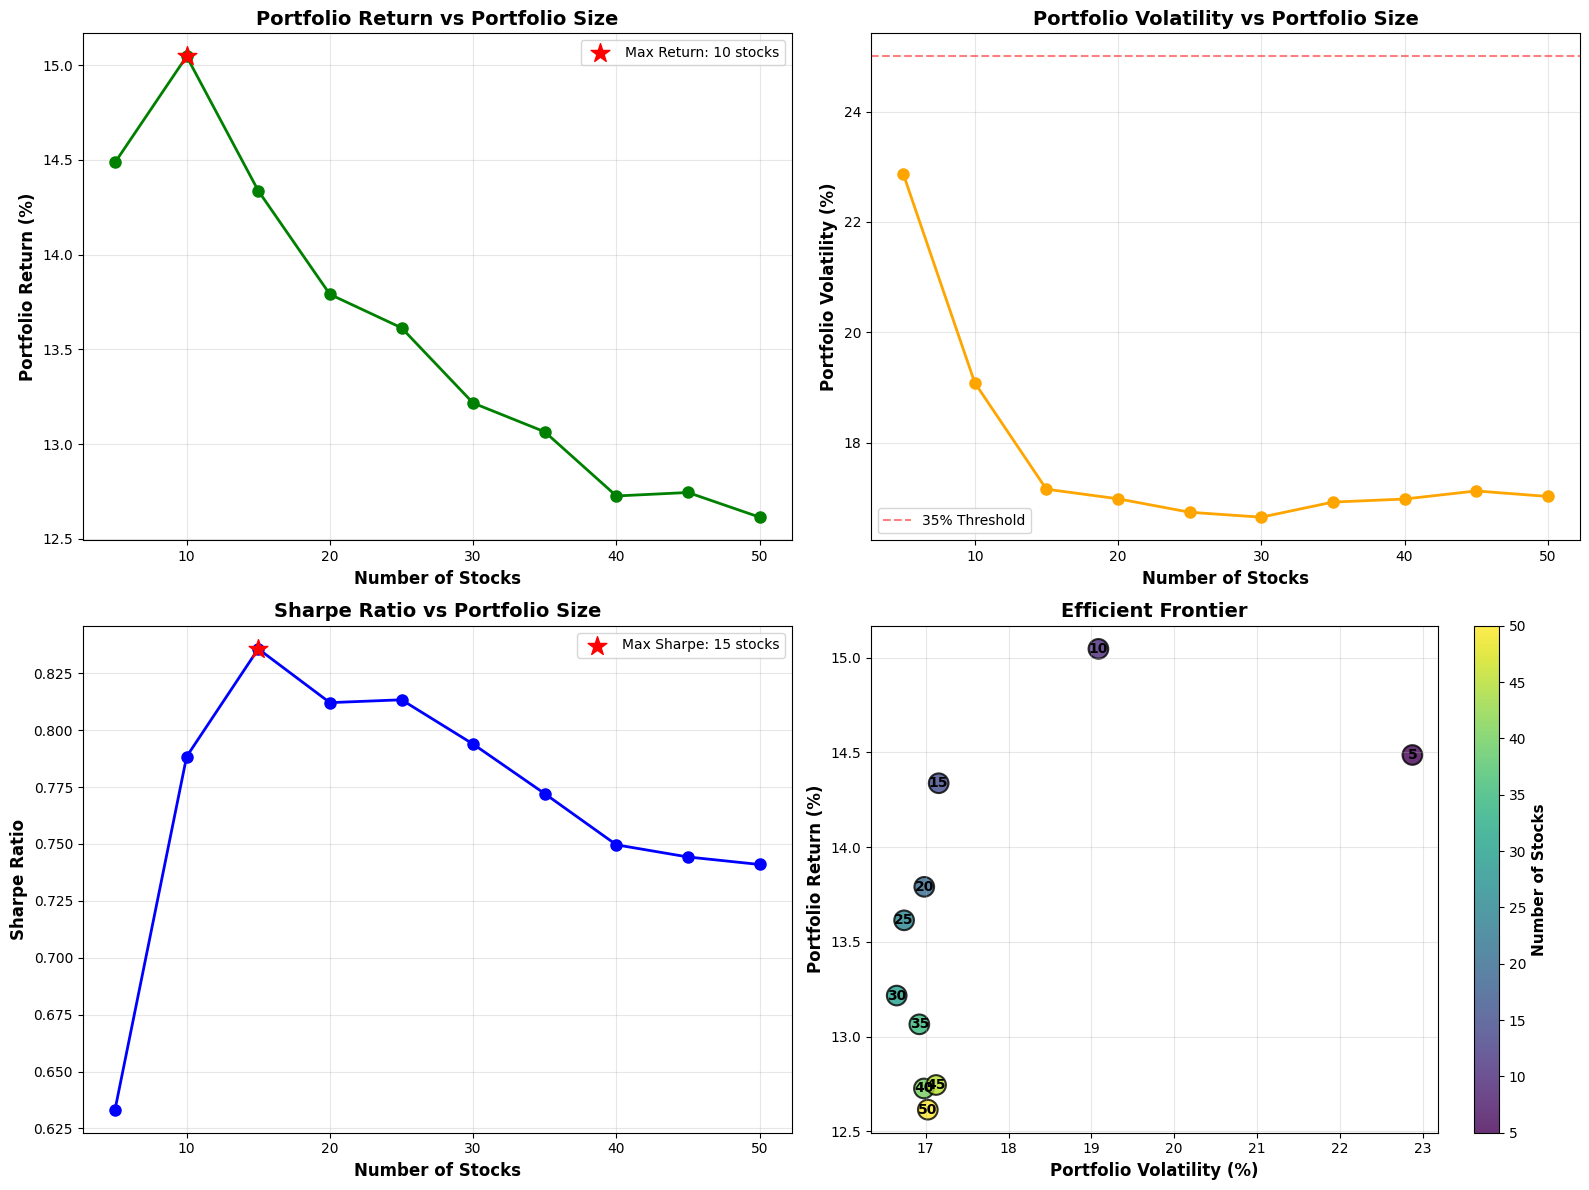


OPTIMAL PORTFOLIO RECOMMENDATIONS

1. MAXIMUM SHARPE RATIO (Best Risk-Adjusted Return):
   Optimal Number of Stocks: 15
   Portfolio Return: 14.34%
   Portfolio Volatility: 17.16%
   Sharpe Ratio: 0.836

2. MAXIMUM RETURN:
   Optimal Number of Stocks: 10
   Portfolio Return: 15.05%
   Portfolio Volatility: 19.09%
   Sharpe Ratio: 0.788

3. ELBOW METHOD (Diminishing Returns):
   Optimal Number of Stocks: 10
   Portfolio Return: 15.05%
   Portfolio Volatility: 19.09%
   Sharpe Ratio: 0.788

RECOMMENDATION: Use the portfolio with the MAXIMUM SHARPE RATIO
                (15 stocks)

OPTIMAL PORTFOLIO COMPOSITION
Rank   Ticker       Sector                         Name                                Geo Mean %      Std Dev %   
------------------------------------------------------------------------------------------------------------------------
1      ROST         Consumer Discretionary         Ross Stores, Inc.                           16.65       32.98
2      EXPD         Industrials 

In [ ]:
print("\nStarting portfolio size optimization...")
volatility_threshold = 35
# Define portfolio sizes to test
portfolio_sizes = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

# Run optimization
results, results_df = optimize_portfolio_size(metrics_df, df_filtered, portfolio_sizes, volatility_threshold)

# Plot results
plot_optimization_results(results_df)

# Find optimal portfolio
optimal_stocks, optimal_metrics = find_optimal_portfolio(results, results_df)

# Display optimal portfolio
display_optimal_portfolio(optimal_stocks)

###Data Visualisation:
Even though having 5 stocks has the highest return and sharpe ratio, but it goes against the constraint of a combination of stocks in a market sector must not exceed 30% of the portfolio.

The portfolio with 10 stocks is suitable in this case.

From the figure that shows the geo mean return to stock volatility, increasing stock volatility from 35% onwards does not show any significant increase in geo mean return, so futher volatility threshold is ignored.


Starting portfolio size optimization...

PORTFOLIO SIZE OPTIMIZATION
N Stocks     Portfolio Return %   Portfolio Volatility % Sharpe Ratio   
----------------------------------------------------------------------------------------------------
10                        15.05                19.09          0.788
20                        13.79                16.98          0.812
25                        13.61                16.74          0.813
30                        13.22                16.65          0.794
35                        13.07                16.92          0.772
40                        12.73                16.98          0.750
45                        12.75                17.12          0.744
50                        12.61                17.02          0.741


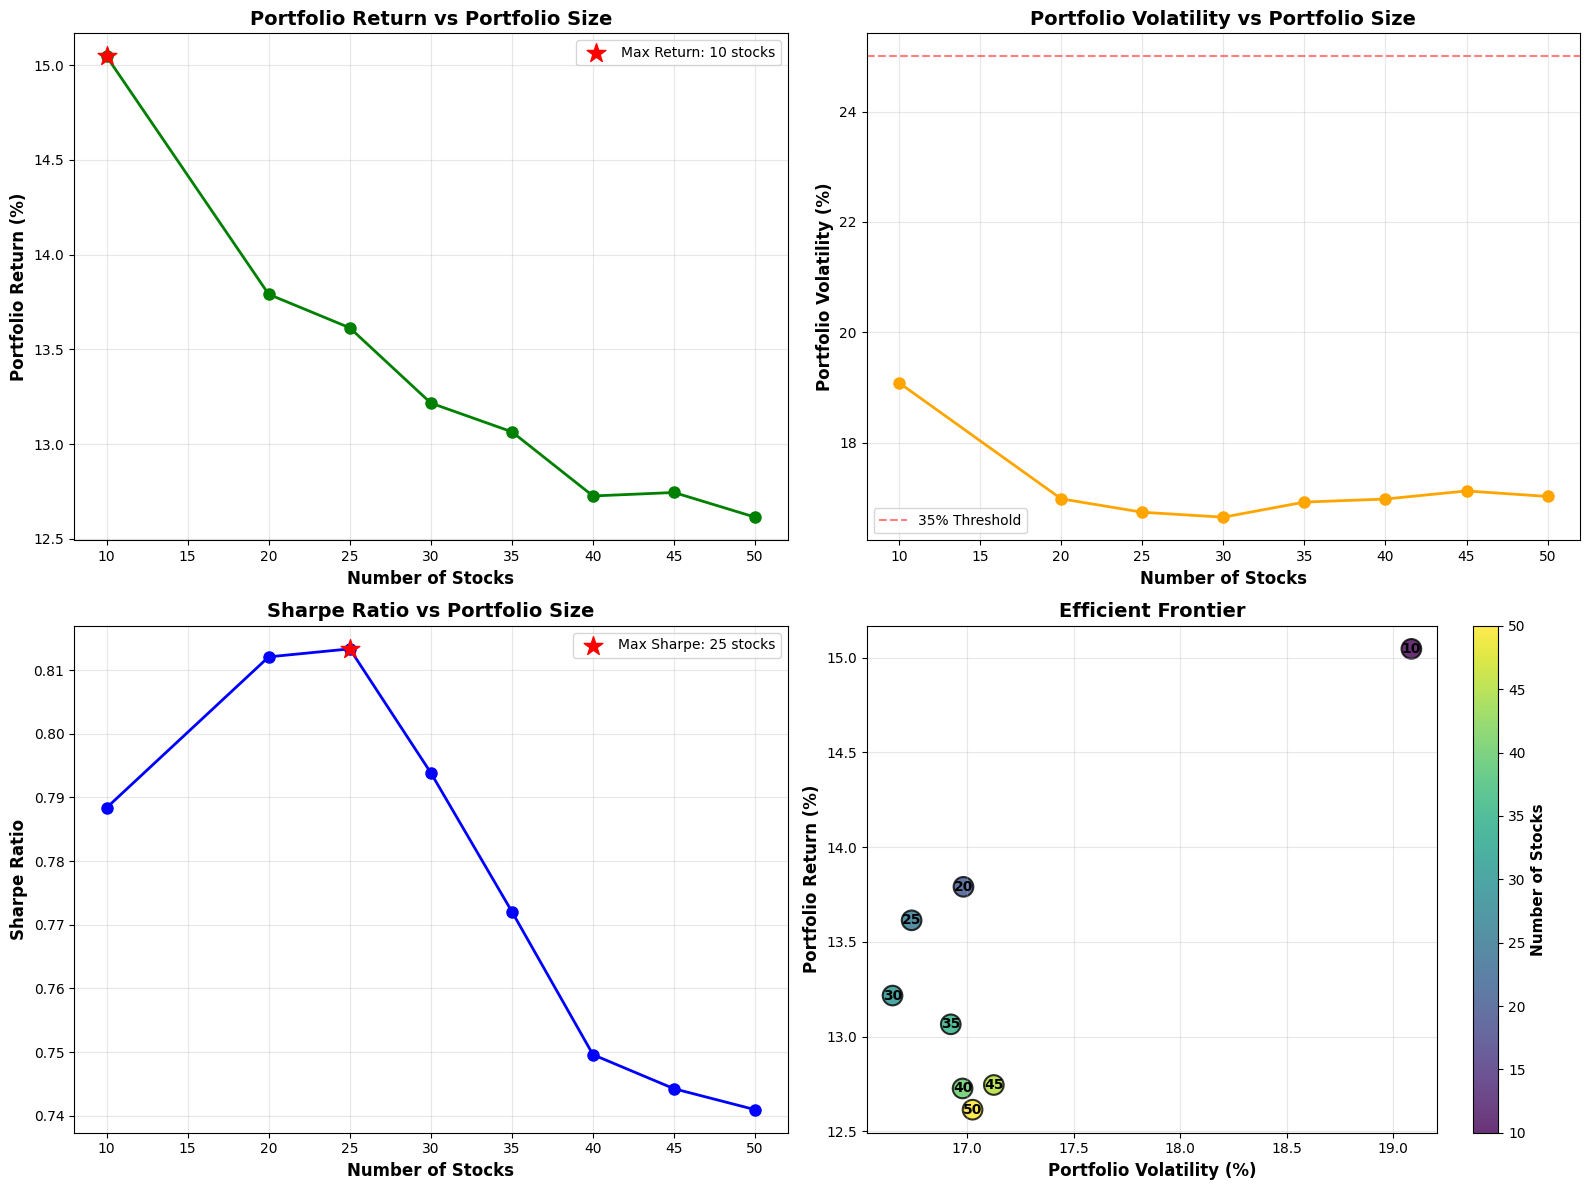


OPTIMAL PORTFOLIO RECOMMENDATIONS

1. MAXIMUM SHARPE RATIO (Best Risk-Adjusted Return):
   Optimal Number of Stocks: 25
   Portfolio Return: 13.61%
   Portfolio Volatility: 16.74%
   Sharpe Ratio: 0.813

2. MAXIMUM RETURN:
   Optimal Number of Stocks: 10
   Portfolio Return: 15.05%
   Portfolio Volatility: 19.09%
   Sharpe Ratio: 0.788

3. ELBOW METHOD (Diminishing Returns):
   Optimal Number of Stocks: 10
   Portfolio Return: 15.05%
   Portfolio Volatility: 19.09%
   Sharpe Ratio: 0.788

RECOMMENDATION: Use the portfolio with the MAXIMUM SHARPE RATIO
                (25 stocks)

OPTIMAL PORTFOLIO COMPOSITION
Rank   Ticker       Sector                         Name                                Geo Mean %      Std Dev %   
------------------------------------------------------------------------------------------------------------------------
1      ROST         Consumer Discretionary         Ross Stores, Inc.                           16.65       32.98
2      EXPD         Industrials 

In [ ]:
# Main execution
volatility_threshold = 35
print("\nStarting portfolio size optimization...")

# Define portfolio sizes to test
portfolio_sizes = [10, 20, 25, 30, 35, 40, 45, 50]

# Run optimization
results, results_df = optimize_portfolio_size(metrics_df, df_filtered, portfolio_sizes, volatility_threshold)

# Plot results
plot_optimization_results(results_df)

# Find optimal portfolio
optimal_stocks, optimal_metrics = find_optimal_portfolio(results, results_df)

# Display optimal portfolio
display_optimal_portfolio(optimal_stocks)

Given individual volatility of each stock is less than 35%, we choose the number of stocks with max return, in this case is 10.

In [ ]:
def create_fixed_portfolio(metrics_df, n_stocks, volatility_threshold=35):
    """
    Create a portfolio with top N stocks by geometric mean return.
    """
    # Filter by volatility
    eligible = metrics_df[metrics_df['std_dev'] < volatility_threshold].copy()

    # Sort by geometric mean (descending)
    eligible = eligible.sort_values('geometric_mean', ascending=False)

    # Select top N
    selected = eligible.head(n_stocks)

    print("\n" + "="*120)
    print(f"SELECTED PORTFOLIO: TOP {n_stocks} STOCKS BY GEOMETRIC MEAN (Volatility < {volatility_threshold}%)")
    print("="*120)
    print(f"{'Rank':<6} {'Ticker':<12} {'Sector':<30} {'Geo Mean %':<15} {'Std Dev %':<12}")
    print("-"*120)

    for rank, (_, stock) in enumerate(selected.iterrows(), 1):
        print(f"{rank:<6} {stock['ticker']:<12} {stock['sector']:<30} "
              f"{stock['geometric_mean']:>13.2f} {stock['std_dev']:>11.2f}")

    print("="*120)

    return selected


def backtest_portfolio(portfolio_stocks, df_data, initial_investment, period_name=None):
    """
    Backtest portfolio on a single dataset.

    Parameters:
    - portfolio_stocks: DataFrame with selected stocks
    - df_data: Price dataframe for ONE period
    - initial_investment: Starting capital
    - period_name: Optional label ('Train', 'Test', etc.)

    Returns:
    - portfolio_value: DataFrame with portfolio performance
    - shares: Dictionary of shares held
    """

    # Get stock columns
    stock_cols = portfolio_stocks['bloomberg_col'].tolist()

    # Extract prices
    portfolio_prices = df_data[stock_cols].copy()

    # Equal weighting
    n_stocks = len(stock_cols)
    weight_per_stock = 1 / n_stocks
    investment_per_stock = initial_investment * weight_per_stock

    # Buy shares at first available price
    shares = {}

    for col in stock_cols:
        first_price = portfolio_prices[col].dropna().iloc[0]
        shares[col] = investment_per_stock / first_price

    # Portfolio values
    portfolio_value = pd.DataFrame(index=portfolio_prices.index)

    for col in stock_cols:
        portfolio_value[col] = portfolio_prices[col] * shares[col]

    # Total portfolio value
    portfolio_value['Total'] = portfolio_value[stock_cols].sum(axis=1)

    # Daily returns
    portfolio_value['Daily_Return'] = portfolio_value['Total'].pct_change()

    # Cumulative return
    portfolio_value['Cumulative_Return'] = (
        1 + portfolio_value['Daily_Return']
    ).cumprod() - 1

    # Optional period label
    if period_name is not None:
        portfolio_value['Period'] = period_name

    return portfolio_value, shares

In [ ]:
portfolio_stocks = create_fixed_portfolio(metrics_df, n_stocks=10, volatility_threshold=35)
stock_cols = portfolio_stocks['bloomberg_col'].tolist()

df_train = df.loc['1993-09-07':'2013-01-01']
df_test  = df.loc['2013-01-01':'2019-07-31']

stock_cols = optimal_stocks['bloomberg_col'].tolist()[:10]

# Keep only selected stocks
price_data = df_train[stock_cols].copy()

# Remove rows with missing values
price_data = price_data.dropna()

print(f"Training period shape: {price_data.shape}")




SELECTED PORTFOLIO: TOP 10 STOCKS BY GEOMETRIC MEAN (Volatility < 35%)
Rank   Ticker       Sector                         Geo Mean %      Std Dev %   
------------------------------------------------------------------------------------------------------------------------
1      ROST         Consumer Discretionary                 16.65       32.98
2      EXPD         Industrials                            14.99       33.56
3      APH          Information Technology                 13.83       33.83
4      CHRW         Industrials                            13.74       30.98
5      FAST         Industrials                            13.53       32.32
6      TJX          Consumer Discretionary                 13.32       29.71
7      DGX          Health Care                            13.20       28.28
8      ORLY         Consumer Discretionary                 13.11       30.91
9      MTD          Health Care                            12.40       28.62
10     DHR          Health Care   

#Initialisation of equal weights and relative weights distribution.

In [ ]:

# Daily returns
returns = price_data.pct_change().dropna()

def portfolio_return(weights, geo_returns):
    return -np.dot(weights, geo_returns)  # negative because we minimise

def portfolio_volatility(weights, cov_matrix):
    return np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))

# Covariance matrix (annualized)
cov_matrix = returns.cov().values * 252

# Constraints
constraints = [
    {'type': 'eq',  'fun': lambda w: np.sum(w) - 1},               # weights sum to 1
    {'type': 'ineq','fun': lambda w: 0.35 - portfolio_volatility(w, cov_matrix)}  # vol <= 35%
]

n_assets= len(stock_cols)

initial_weights = np.ones(n_assets)/n_assets

# Annualized geometric mean return
geo_returns = []

for col in returns.columns:

    compounded_growth = (1 + returns[col]).prod()

    n_years = len(returns) / 252

    geometric_return = compounded_growth**(1 / n_years) - 1

    geo_returns.append(geometric_return)

# Convert to numpy array
geo_returns = np.array(geo_returns)

bounds = tuple((0.05, 0.25) for _ in range(n_assets))

result = minimize(
    portfolio_return,           # maximise return (minimise negative return)
    initial_weights,
    args=(geo_returns,),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

optimal_weights = result.x
print(optimal_weights)

[0.05 0.05 0.05 0.15 0.05 0.05 0.25 0.25 0.05 0.05]


In [ ]:
eq_vol = portfolio_volatility(initial_weights, cov_matrix)
print(f"Equal weight portfolio vol: {eq_vol*100:.2f}%")

Equal weight portfolio vol: 19.09%


In [ ]:
target_returns = np.linspace(geo_returns.min(), geo_returns.max(), 200)
frontier_vols, frontier_rets, frontier_weights = [], [], []

for target in target_returns:
    cons = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
        {'type': 'eq', 'fun': lambda w: np.dot(w, geo_returns) - target}
    ]
    res = minimize(
        lambda w: portfolio_volatility(w, cov_matrix),
        initial_weights, method='SLSQP',
        bounds=bounds, constraints=cons
    )
    if res.success:
        frontier_vols.append(portfolio_volatility(res.x, cov_matrix))
        frontier_rets.append(np.dot(res.x, geo_returns))
        frontier_weights.append(res.x)

# Instead of hardcoding 0.25, set it relative to your actual frontier
min_achievable_vol = min(frontier_vols)
vol_cap = min_achievable_vol * 1.10  # 10% above minimum, gives optimiser room

print(f"Using vol cap of: {vol_cap*100:.2f}%")

valid = [(r, w) for r, v, w in zip(frontier_rets, frontier_vols, frontier_weights) if v <= vol_cap]
best_return, best_weights = max(valid, key=lambda x: x[0])

Using vol cap of: 19.88%


In [ ]:
returns_train = df_train[stock_cols].pct_change()
returns_test  = df_test[stock_cols].pct_change()

# ── EQUAL WEIGHTS ────────────────────────────────────────────
equal_weights = np.array([1 / len(stock_cols)] * len(stock_cols))

portfolio_return_train_eq = returns_train.dot(equal_weights)
portfolio_return_test_eq  = returns_test.dot(equal_weights)

# ── OPTIMISED WEIGHTS ────────────────────────────────────────
portfolio_return_train_opt = returns_train.dot(optimal_weights)
portfolio_return_test_opt  = returns_test.dot(optimal_weights)


#Effecient frontier of using optimal weights

Frontier points: 161  |  Failed: 139/300

Max-return portfolio  vol=19.07%  ret=12.39%
Weights: [0.05   0.05   0.05   0.1751 0.05   0.05   0.25   0.2241 0.0508 0.05  ]

--- Max Return (Vol ≤ Cap) Weight Breakdown ---
  DGX US Equity   25.00%  █████████████████████████
  ORLY US Equity   22.41%  ██████████████████████
  CHRW US Equity   17.51%  █████████████████
  MTD US Equity    5.08%  █████
  FAST US Equity    5.00%  █████
  EXPD US Equity    5.00%  █████
  TJX US Equity    5.00%  █████
  ROST US Equity    5.00%  █████
  APH US Equity    5.00%  █████
  DHR US Equity    5.00%  █████

  Total: 100.00%


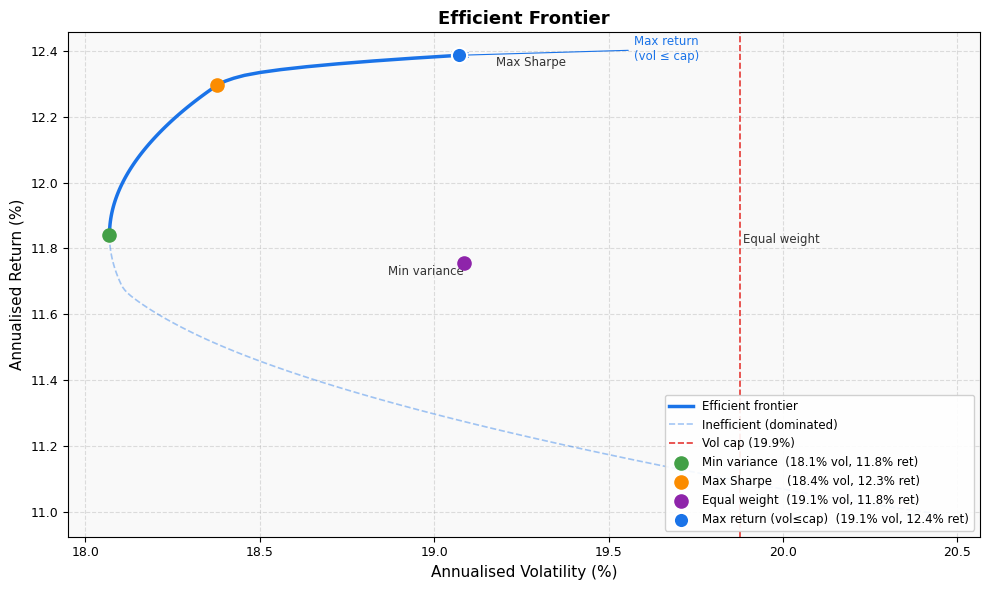

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import minimize

# ── helpers ────────────────────────────────────────────────────────────────────
def portfolio_return_val(weights, geo_returns):
    return np.dot(weights, geo_returns)

def portfolio_vol(weights, cov_matrix):
    return np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))

def negative_sharpe(weights, geo_returns, cov_matrix, rf=0):
    r = portfolio_return_val(weights, geo_returns)
    v = portfolio_vol(weights, cov_matrix)
    return -(r - rf) / v if v > 1e-8 else 0

# ── inputs (plug in your own) ──────────────────────────────────────────────────
# geo_returns  : np.array of shape (n_assets,)  — annualised geometric returns
# cov_matrix   : np.array of shape (n_assets, n_assets) — already annualised (*252)
# n_assets, bounds, initial_weights — same as your existing setup

# ── 1. efficient frontier sweep ────────────────────────────────────────────────
target_returns = np.linspace(geo_returns.min(), geo_returns.max() * 0.95, 300)

frontier_vols, frontier_rets, frontier_weights = [], [], []
failed = 0

for target in target_returns:
    cons = [
        {'type': 'eq',  'fun': lambda w:       np.sum(w) - 1},
        {'type': 'eq',  'fun': lambda w, t=target: np.dot(w, geo_returns) - t},
    ]
    res = minimize(
        portfolio_vol,
        initial_weights,
        args=(cov_matrix,),
        method='SLSQP',
        bounds=bounds,
        constraints=cons,
        options={'ftol': 1e-9, 'maxiter': 1000}
    )
    if res.success:
        frontier_vols.append(portfolio_vol(res.x, cov_matrix))
        frontier_rets.append(np.dot(res.x, geo_returns))
        frontier_weights.append(res.x)
    else:
        failed += 1

print(f"Frontier points: {len(frontier_vols)}  |  Failed: {failed}/{len(target_returns)}")

frontier_vols = np.array(frontier_vols)
frontier_rets = np.array(frontier_rets)

# ── 2. key portfolios ──────────────────────────────────────────────────────────
base_cons = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]

# minimum variance
res_minvol = minimize(portfolio_vol, initial_weights,
                      args=(cov_matrix,), method='SLSQP',
                      bounds=bounds, constraints=base_cons)
minvol_vol = portfolio_vol(res_minvol.x, cov_matrix)
minvol_ret = portfolio_return_val(res_minvol.x, geo_returns)

# maximum Sharpe
res_sharpe = minimize(negative_sharpe, initial_weights,
                      args=(geo_returns, cov_matrix, 0), method='SLSQP',
                      bounds=bounds, constraints=base_cons)
sharpe_vol = portfolio_vol(res_sharpe.x, cov_matrix)
sharpe_ret = portfolio_return_val(res_sharpe.x, geo_returns)

# equal weight
eq_w   = np.array([1 / n_assets] * n_assets)
eq_vol = portfolio_vol(eq_w, cov_matrix)
eq_ret = portfolio_return_val(eq_w, geo_returns)

# max return within vol cap
min_achievable_vol = frontier_vols.min()
vol_cap = min_achievable_vol * 1.10
valid_mask = frontier_vols <= vol_cap

if valid_mask.any():
    best_idx   = frontier_rets[valid_mask].argmax()
    best_vol   = frontier_vols[valid_mask][best_idx]
    best_ret   = frontier_rets[valid_mask][best_idx]
    best_w     = frontier_weights[np.where(valid_mask)[0][best_idx]]
    print(f"\nMax-return portfolio  vol={best_vol*100:.2f}%  ret={best_ret*100:.2f}%")
    print(f"Weights: {np.round(best_w, 4)}")

    # ── weight breakdown by stock ──────────────────────────────────────────────────
    print("\n--- Max Return (Vol ≤ Cap) Weight Breakdown ---")
    weight_df = pd.DataFrame({
        'Stock':  stock_cols,
        'Weight': best_w,
        'Weight %': best_w * 100
    }).sort_values('Weight', ascending=False).reset_index(drop=True)

    for _, row in weight_df.iterrows():
        bar = '█' * int(row['Weight %'] / 1)   # 1 block per 1%
        print(f"  {row['Stock']:<6}  {row['Weight %']:>6.2f}%  {bar}")

    print(f"\n  Total: {best_w.sum()*100:.2f}%")

else:
    print("No valid points under vol cap — widen the cap.")
    best_vol = best_ret = None

# ── 3. plot ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_facecolor('#f9f9f9')
fig.patch.set_facecolor('#ffffff')

# split frontier into efficient (upper) and inefficient (lower) halves
# the efficient portion starts at the minimum-variance point
minvol_idx = frontier_vols.argmin()
eff_vols = frontier_vols[minvol_idx:]
eff_rets = frontier_rets[minvol_idx:]
ineff_vols = frontier_vols[:minvol_idx]
ineff_rets = frontier_rets[:minvol_idx]

ax.plot(eff_vols * 100,   eff_rets * 100,   color='#1a73e8', linewidth=2.5, label='Efficient frontier')
ax.plot(ineff_vols * 100, ineff_rets * 100, color='#1a73e8', linewidth=1.2,
        linestyle='--', alpha=0.4, label='Inefficient (dominated)')

# vol cap line
ax.axvline(vol_cap * 100, color='#e53935', linewidth=1.2, linestyle='--',
           label=f'Vol cap ({vol_cap*100:.1f}%)')

# key portfolio dots
ax.scatter(minvol_vol * 100, minvol_ret * 100, s=90, color='#43a047',
           zorder=5, label=f'Min variance  ({minvol_vol*100:.1f}% vol, {minvol_ret*100:.1f}% ret)')
ax.scatter(sharpe_vol * 100, sharpe_ret * 100, s=90, color='#fb8c00',
           zorder=5, label=f'Max Sharpe    ({sharpe_vol*100:.1f}% vol, {sharpe_ret*100:.1f}% ret)')
ax.scatter(eq_vol * 100,     eq_ret * 100,     s=90, color='#8e24aa',
           zorder=5, label=f'Equal weight  ({eq_vol*100:.1f}% vol, {eq_ret*100:.1f}% ret)')

if best_vol is not None:
    ax.scatter(best_vol * 100, best_ret * 100, s=120, color='#1a73e8', edgecolors='white',
               linewidths=1.5, zorder=6,
               label=f'Max return (vol≤cap)  ({best_vol*100:.1f}% vol, {best_ret*100:.1f}% ret)')

# annotations
offset = {'min': (8, -12), 'sharpe': (8, 6), 'eq': (8, 6), 'best': (8, -14)}
for (x, y, lbl, off) in [
    (minvol_vol, minvol_ret, 'Min variance',       offset['min']),
    (sharpe_vol, sharpe_ret, 'Max Sharpe',          offset['sharpe']),
    (eq_vol,     eq_ret,     'Equal weight',        offset['eq']),
]:
    ax.annotate(lbl, xy=(x*100, y*100),
                xytext=(x*100 + off[0]/10, y*100 + off[1]/100),
                fontsize=8.5, color='#333333')

if best_vol is not None:
    ax.annotate('Max return\n(vol ≤ cap)', xy=(best_vol*100, best_ret*100),
                xytext=(best_vol*100 + 0.5, best_ret*100 - 0.015),
                fontsize=8.5, color='#1a73e8',
                arrowprops=dict(arrowstyle='->', color='#1a73e8', lw=0.8))

ax.set_xlabel('Annualised Volatility (%)', fontsize=11)
ax.set_ylabel('Annualised Return (%)',     fontsize=11)
ax.set_title('Efficient Frontier', fontsize=13, fontweight='bold')
ax.legend(fontsize=8.5, loc='lower right', framealpha=0.9)
ax.grid(True, linestyle='--', alpha=0.4)
ax.tick_params(labelsize=9)

plt.tight_layout()
plt.savefig('efficient_frontier.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# your current max-Sharpe weights
current_ret = portfolio_return_val(optimal_weights, geo_returns)
current_vol = portfolio_vol(optimal_weights, cov_matrix)
current_sharpe = current_ret / current_vol

# new max-return-within-vol-cap weights
best_ret_val = portfolio_return_val(best_w, geo_returns)
best_vol_val = portfolio_vol(best_w, cov_matrix)
best_sharpe  = best_ret_val / best_vol_val

print("                  Return     Vol     Sharpe")
print(f"Max Sharpe (old): {current_ret*100:.2f}%    {current_vol*100:.2f}%   {current_sharpe:.3f}")
print(f"Max Return (new): {best_ret_val*100:.2f}%    {best_vol_val*100:.2f}%   {best_sharpe:.3f}")

                  Return     Vol     Sharpe
Max Sharpe (old): 12.39%    19.17%   0.647
Max Return (new): 12.39%    19.07%   0.649


###The max return weight distribution does not outperform optimal weights, thus we stick with using optimal weigths

#Initiation of dynamic weights based on 15 days momentum

In [ ]:
lookback = 15
rebalance_freq = 15

dynamic_weights_matrix = pd.DataFrame(
    index=returns_test.index,
    columns=stock_cols,
    dtype=float
)

current_weights = equal_weights.copy()

for t in range(len(returns_test)):
    if t % rebalance_freq == 0 and t >= lookback:
        recent = returns_test.iloc[t - lookback:t]

        # volatility per stock over lookback window
        recent_vol = recent.std()

        # avoid division by zero
        recent_vol = recent_vol.replace(0, np.nan)
        inv_vol = 1 / recent_vol

        # stocks with NaN vol (zero variance) get zero allocation
        inv_vol = inv_vol.fillna(0)

        if inv_vol.sum() > 0:
            current_weights = (inv_vol / inv_vol.sum()).values
        else:
            current_weights = equal_weights.copy()

    dynamic_weights_matrix.iloc[t] = current_weights

portfolio_return_test_dynamic = (returns_test * dynamic_weights_matrix).sum(axis=1)

##Dynamic-weight portfolio daily return

In [ ]:
# element-wise multiply each day's returns by that day's weights
portfolio_return_test_dynamic = (returns_test * dynamic_weights_matrix).sum(axis=1)
portfolio_return_train_dynamic = None  # weights are test-only; train stays fixed

print(f"\nDynamic portfolio daily return stats:")
print(f"  Mean:  {portfolio_return_test_dynamic.mean()*100:.4f}%")
print(f"  Std:   {portfolio_return_test_dynamic.std()*100:.4f}%")
print(f"  Sharpe: {portfolio_return_test_dynamic.mean() / portfolio_return_test_dynamic.std() * np.sqrt(252):.3f}")


Dynamic portfolio daily return stats:
  Mean:  0.0449%
  Std:   0.7187%
  Sharpe: 0.992


#Features initialising, in total 10

In [ ]:
def cross_sectional(returns, index):
    cs = pd.DataFrame(index=index)
    cs['pct_positive']  = (returns > 0).sum(axis=1).shift(1) / len(stock_cols)
    cs['max_return']    = returns.max(axis=1).shift(1)
    cs['min_return']    = returns.min(axis=1).shift(1)
    cs['return_spread'] = (returns.max(axis=1) - returns.min(axis=1)).shift(1)
    return cs


#Equal weights training
features_train_eq = pd.DataFrame(index=df_train.index)
features_train_eq['avg_return_1d']  = portfolio_return_train_eq.shift(1)
features_train_eq['avg_return_5d']  = portfolio_return_train_eq.rolling(5).mean().shift(1)
features_train_eq['avg_return_10d'] = portfolio_return_train_eq.rolling(10).mean().shift(1)
features_train_eq['avg_return_20d'] = portfolio_return_train_eq.rolling(20).mean().shift(1)
features_train_eq['volatility_5d']  = portfolio_return_train_eq.rolling(5).std().shift(1)
features_train_eq['volatility_10d'] = portfolio_return_train_eq.rolling(10).std().shift(1)
features_train_eq['volatility_20d'] = portfolio_return_train_eq.rolling(20).std().shift(1)
features_train_eq['momentum_5d']    = portfolio_return_train_eq.rolling(5).sum().shift(1)
features_train_eq['momentum_10d']   = portfolio_return_train_eq.rolling(10).sum().shift(1)
features_train_eq['momentum_20d']   = portfolio_return_train_eq.rolling(20).sum().shift(1)
features_train_eq = features_train_eq.join(cross_sectional(returns_train, df_train.index))

#testing set
features_test_eq = pd.DataFrame(index=df_test.index)
features_test_eq['avg_return_1d']  = portfolio_return_test_eq.shift(1)
features_test_eq['avg_return_5d']  = portfolio_return_test_eq.rolling(5).mean().shift(1)
features_test_eq['avg_return_10d'] = portfolio_return_test_eq.rolling(10).mean().shift(1)
features_test_eq['avg_return_20d'] = portfolio_return_test_eq.rolling(20).mean().shift(1)
features_test_eq['volatility_5d']  = portfolio_return_test_eq.rolling(5).std().shift(1)
features_test_eq['volatility_10d'] = portfolio_return_test_eq.rolling(10).std().shift(1)
features_test_eq['volatility_20d'] = portfolio_return_test_eq.rolling(20).std().shift(1)
features_test_eq['momentum_5d']    = portfolio_return_test_eq.rolling(5).sum().shift(1)
features_test_eq['momentum_10d']   = portfolio_return_test_eq.rolling(10).sum().shift(1)
features_test_eq['momentum_20d']   = portfolio_return_test_eq.rolling(20).sum().shift(1)
features_test_eq = features_test_eq.join(cross_sectional(returns_test, df_test.index))

# Optimised weights training set
features_train_opt = pd.DataFrame(index=df_train.index)
features_train_opt['avg_return_1d']  = portfolio_return_train_opt.shift(1)
features_train_opt['avg_return_5d']  = portfolio_return_train_opt.rolling(5).mean().shift(1)
features_train_opt['avg_return_10d'] = portfolio_return_train_opt.rolling(10).mean().shift(1)
features_train_opt['avg_return_20d'] = portfolio_return_train_opt.rolling(20).mean().shift(1)
features_train_opt['volatility_5d']  = portfolio_return_train_opt.rolling(5).std().shift(1)
features_train_opt['volatility_10d'] = portfolio_return_train_opt.rolling(10).std().shift(1)
features_train_opt['volatility_20d'] = portfolio_return_train_opt.rolling(20).std().shift(1)
features_train_opt['momentum_5d']    = portfolio_return_train_opt.rolling(5).sum().shift(1)
features_train_opt['momentum_10d']   = portfolio_return_train_opt.rolling(10).sum().shift(1)
features_train_opt['momentum_20d']   = portfolio_return_train_opt.rolling(20).sum().shift(1)
features_train_opt = features_train_opt.join(cross_sectional(returns_train, df_train.index))

#Testing set
features_test_opt = pd.DataFrame(index=df_test.index)
features_test_opt['avg_return_1d']  = portfolio_return_test_opt.shift(1)
features_test_opt['avg_return_5d']  = portfolio_return_test_opt.rolling(5).mean().shift(1)
features_test_opt['avg_return_10d'] = portfolio_return_test_opt.rolling(10).mean().shift(1)
features_test_opt['avg_return_20d'] = portfolio_return_test_opt.rolling(20).mean().shift(1)
features_test_opt['volatility_5d']  = portfolio_return_test_opt.rolling(5).std().shift(1)
features_test_opt['volatility_10d'] = portfolio_return_test_opt.rolling(10).std().shift(1)
features_test_opt['volatility_20d'] = portfolio_return_test_opt.rolling(20).std().shift(1)
features_test_opt['momentum_5d']    = portfolio_return_test_opt.rolling(5).sum().shift(1)
features_test_opt['momentum_10d']   = portfolio_return_test_opt.rolling(10).sum().shift(1)
features_test_opt['momentum_20d']   = portfolio_return_test_opt.rolling(20).sum().shift(1)
features_test_opt = features_test_opt.join(cross_sectional(returns_test, df_test.index))

# ── DYNAMIC WEIGHTS TEST SET ─────────────────────────────────
features_test_dynamic = pd.DataFrame(index=df_test.index)
features_test_dynamic['avg_return_1d']  = portfolio_return_test_dynamic.shift(1)
features_test_dynamic['avg_return_5d']  = portfolio_return_test_dynamic.rolling(5).mean().shift(1)
features_test_dynamic['avg_return_10d'] = portfolio_return_test_dynamic.rolling(10).mean().shift(1)
features_test_dynamic['avg_return_20d'] = portfolio_return_test_dynamic.rolling(20).mean().shift(1)
features_test_dynamic['volatility_5d']  = portfolio_return_test_dynamic.rolling(5).std().shift(1)
features_test_dynamic['volatility_10d'] = portfolio_return_test_dynamic.rolling(10).std().shift(1)
features_test_dynamic['volatility_20d'] = portfolio_return_test_dynamic.rolling(20).std().shift(1)
features_test_dynamic['momentum_5d']    = portfolio_return_test_dynamic.rolling(5).sum().shift(1)
features_test_dynamic['momentum_10d']   = portfolio_return_test_dynamic.rolling(10).sum().shift(1)
features_test_dynamic['momentum_20d']   = portfolio_return_test_dynamic.rolling(20).sum().shift(1)
features_test_dynamic = features_test_dynamic.join(cross_sectional(returns_test, df_test.index))


Since the dynamic weights only apply to the test period, the train set stays the same as the optimised weights train set

#KNNImputer and StandardScaler

In [ ]:
# ── EQUAL WEIGHTS ────────────────────────────────────────────
imputer_eq          = KNNImputer(n_neighbors=10, weights='distance')
X_train_eq_imputed  = imputer_eq.fit_transform(features_train_eq)
X_test_eq_imputed   = imputer_eq.transform(features_test_eq)

# Align targets
target_train_eq = portfolio_return_train_eq.loc[features_train_eq.index] * 100
target_test_eq  = portfolio_return_test_eq.loc[features_test_eq.index]   * 100

# Drop NaN from target, then match X to the same clean index
train_valid_idx     = target_train_eq.dropna().index
target_train_eq     = target_train_eq.loc[train_valid_idx]
X_train_eq_imputed  = X_train_eq_imputed[features_train_eq.index.isin(train_valid_idx)]

test_valid_idx      = target_test_eq.dropna().index
target_test_eq      = target_test_eq.loc[test_valid_idx] #slicing and only leaving rows with non Nan values
X_test_eq_imputed   = X_test_eq_imputed[features_test_eq.index.isin(test_valid_idx)]

scaler_eq         = StandardScaler()
X_train_eq_scaled = scaler_eq.fit_transform(X_train_eq_imputed)
X_test_eq_scaled  = scaler_eq.transform(X_test_eq_imputed)

# ── OPTIMISED WEIGHTS ────────────────────────────────────────
imputer_opt          = KNNImputer(n_neighbors=10, weights='distance')
X_train_opt_imputed  = imputer_opt.fit_transform(features_train_opt)
X_test_opt_imputed   = imputer_opt.transform(features_test_opt)

target_train_opt = portfolio_return_train_opt.loc[features_train_opt.index] * 100
target_test_opt  = portfolio_return_test_opt.loc[features_test_opt.index]   * 100

train_valid_idx      = target_train_opt.dropna().index
target_train_opt     = target_train_opt.loc[train_valid_idx]
X_train_opt_imputed  = X_train_opt_imputed[features_train_opt.index.isin(train_valid_idx)]

test_valid_idx       = target_test_opt.dropna().index
target_test_opt      = target_test_opt.loc[test_valid_idx]
X_test_opt_imputed   = X_test_opt_imputed[features_test_opt.index.isin(test_valid_idx)]

scaler_opt         = StandardScaler()
X_train_opt_scaled = scaler_opt.fit_transform(X_train_opt_imputed)
X_test_opt_scaled  = scaler_opt.transform(X_test_opt_imputed)

# ── DYNAMIC WEIGHTS ──────────────────────────────────────────
# train features and imputer are REUSED from optimised weights
# since the train period is identical — only test differs
imputer_dynamic         = KNNImputer(n_neighbors=10, weights='distance')
X_train_dynamic_imputed = imputer_dynamic.fit_transform(features_train_opt)  # same train features
X_test_dynamic_imputed  = imputer_dynamic.transform(features_test_dynamic)   # new dynamic test features

target_train_dynamic = portfolio_return_train_opt.loc[features_train_opt.index] * 100
target_test_dynamic  = portfolio_return_test_dynamic.loc[features_test_dynamic.index] * 100

train_valid_idx          = target_train_dynamic.dropna().index
target_train_dynamic     = target_train_dynamic.loc[train_valid_idx]
X_train_dynamic_imputed  = X_train_dynamic_imputed[features_train_opt.index.isin(train_valid_idx)]

test_valid_idx           = target_test_dynamic.dropna().index
target_test_dynamic      = target_test_dynamic.loc[test_valid_idx]
X_test_dynamic_imputed   = X_test_dynamic_imputed[features_test_dynamic.index.isin(test_valid_idx)]

scaler_dynamic          = StandardScaler()
X_train_dynamic_scaled  = scaler_dynamic.fit_transform(X_train_dynamic_imputed)
X_test_dynamic_scaled   = scaler_dynamic.transform(X_test_dynamic_imputed)

#Model training using
###1. RandomForestRegressor
###2. Multi-variable Linear Regression
###3. GradientBoosterRegressor
###4. AdaBoostRegressor

In [ ]:
# ── EQUAL WEIGHTS ────────────────────────────────────────────
rf_eq = RandomForestRegressor(
    n_estimators=200, max_depth=6,
    min_samples_split=20, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)
rf_eq.fit(X_train_eq_scaled, target_train_eq)
rf_pred_eq = rf_eq.predict(X_test_eq_scaled)

lr_eq = LinearRegression()
lr_eq.fit(X_train_eq_scaled, target_train_eq)
lr_pred_eq = lr_eq.predict(X_test_eq_scaled)

gb_eq = GradientBoostingRegressor(
    n_estimators=200, max_depth=4,
    learning_rate=0.05, subsample=0.8,
    random_state=42
)
gb_eq.fit(X_train_eq_scaled, target_train_eq)
gb_pred_eq = gb_eq.predict(X_test_eq_scaled)

ada_eq = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=4),
    n_estimators=200, learning_rate=0.05,
    random_state=42
)
ada_eq.fit(X_train_eq_scaled, target_train_eq)
ada_pred_eq = ada_eq.predict(X_test_eq_scaled)

# ── OPTIMISED WEIGHTS ────────────────────────────────────────
rf_opt = RandomForestRegressor(
    n_estimators=200, max_depth=6,
    min_samples_split=20, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)
rf_opt.fit(X_train_opt_scaled, target_train_opt)
rf_pred_opt = rf_opt.predict(X_test_opt_scaled)

lr_opt = LinearRegression()
lr_opt.fit(X_train_opt_scaled, target_train_opt)
lr_pred_opt = lr_opt.predict(X_test_opt_scaled)

gb_opt = GradientBoostingRegressor(
    n_estimators=200, max_depth=4,
    learning_rate=0.05, subsample=0.8,
    random_state=42
)
gb_opt.fit(X_train_opt_scaled, target_train_opt)
gb_pred_opt = gb_opt.predict(X_test_opt_scaled)

ada_opt = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=4),
    n_estimators=200, learning_rate=0.05,
    random_state=42
)
ada_opt.fit(X_train_opt_scaled, target_train_opt)
ada_pred_opt = ada_opt.predict(X_test_opt_scaled)

# ── DYNAMIC WEIGHTS ──────────────────────────────────────────
rf_dynamic = RandomForestRegressor(
    n_estimators=200, max_depth=6,
    min_samples_split=20, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)
rf_dynamic.fit(X_train_dynamic_scaled, target_train_dynamic)
rf_pred_dynamic = rf_dynamic.predict(X_test_dynamic_scaled)

lr_dynamic = LinearRegression()
lr_dynamic.fit(X_train_dynamic_scaled, target_train_dynamic)
lr_pred_dynamic = lr_dynamic.predict(X_test_dynamic_scaled)

gb_dynamic = GradientBoostingRegressor(
    n_estimators=200, max_depth=4,
    learning_rate=0.05, subsample=0.8,
    random_state=42
)
gb_dynamic.fit(X_train_dynamic_scaled, target_train_dynamic)
gb_pred_dynamic = gb_dynamic.predict(X_test_dynamic_scaled)

ada_dynamic = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=4),
    n_estimators=200, learning_rate=0.05,
    random_state=42
)
ada_dynamic.fit(X_train_dynamic_scaled, target_train_dynamic)
ada_pred_dynamic = ada_dynamic.predict(X_test_dynamic_scaled)

#Model evaluation

In [ ]:

for label, y_true, rf_pred, lr_pred, gb_pred, ada_pred  in [
    ('EQUAL WEIGHTS',     target_test_eq,  rf_pred_eq,  lr_pred_eq, gb_pred_eq, ada_pred_eq),
    ('OPTIMISED WEIGHTS', target_test_opt, rf_pred_opt, lr_pred_opt, gb_pred_opt, ada_pred_opt),
    ('DYNAMIC WEIGHTS', target_test_dynamic, rf_pred_dynamic, lr_pred_dynamic, gb_pred_dynamic, ada_pred_dynamic)
]:
    print("\n" + "="*80)
    print(label)
    print("="*80)
    for model_name, y_pred in [('Random Forest', rf_pred), ('Linear Regression', lr_pred),('Gradient Boosting Regressor', gb_pred), ('Adaptive Boosting Regressor', ada_pred)]:
        mse  = mean_squared_error(y_true, y_pred)
        rmse = np.sqrt(mse)
        mae  = mean_absolute_error(y_true, y_pred)
        r2   = r2_score(y_true, y_pred)
        dir_acc = ((y_true > 0) == (y_pred > 0)).mean()
        print(f"\n  {model_name}")
        print(f"    MSE:                  {mse:.8f}")
        print(f"    RMSE:                 {rmse:.6f}%")
        print(f"    MAE:                  {mae:.6f}%")
        print(f"    R²:                   {r2:.6f}")
        print(f"    Directional Accuracy: {dir_acc:.4f} ({dir_acc*100:.2f}%)")


EQUAL WEIGHTS

  Random Forest
    MSE:                  0.53380759
    RMSE:                 0.730621%
    MAE:                  0.463264%
    R²:                   -0.006228
    Directional Accuracy: 0.3872 (38.72%)

  Linear Regression
    MSE:                  0.52962643
    RMSE:                 0.727754%
    MAE:                  0.460577%
    R²:                   0.001654
    Directional Accuracy: 0.4833 (48.33%)

  Gradient Boosting Regressor
    MSE:                  0.54708059
    RMSE:                 0.739649%
    MAE:                  0.470458%
    R²:                   -0.031247
    Directional Accuracy: 0.4217 (42.17%)

  Adaptive Boosting Regressor
    MSE:                  0.53406866
    RMSE:                 0.730800%
    MAE:                  0.478620%
    R²:                   -0.006720
    Directional Accuracy: 0.3855 (38.55%)

OPTIMISED WEIGHTS

  Random Forest
    MSE:                  0.55271131
    RMSE:                 0.743446%
    MAE:                  0.4

#Portfolio simulation and Evaluation

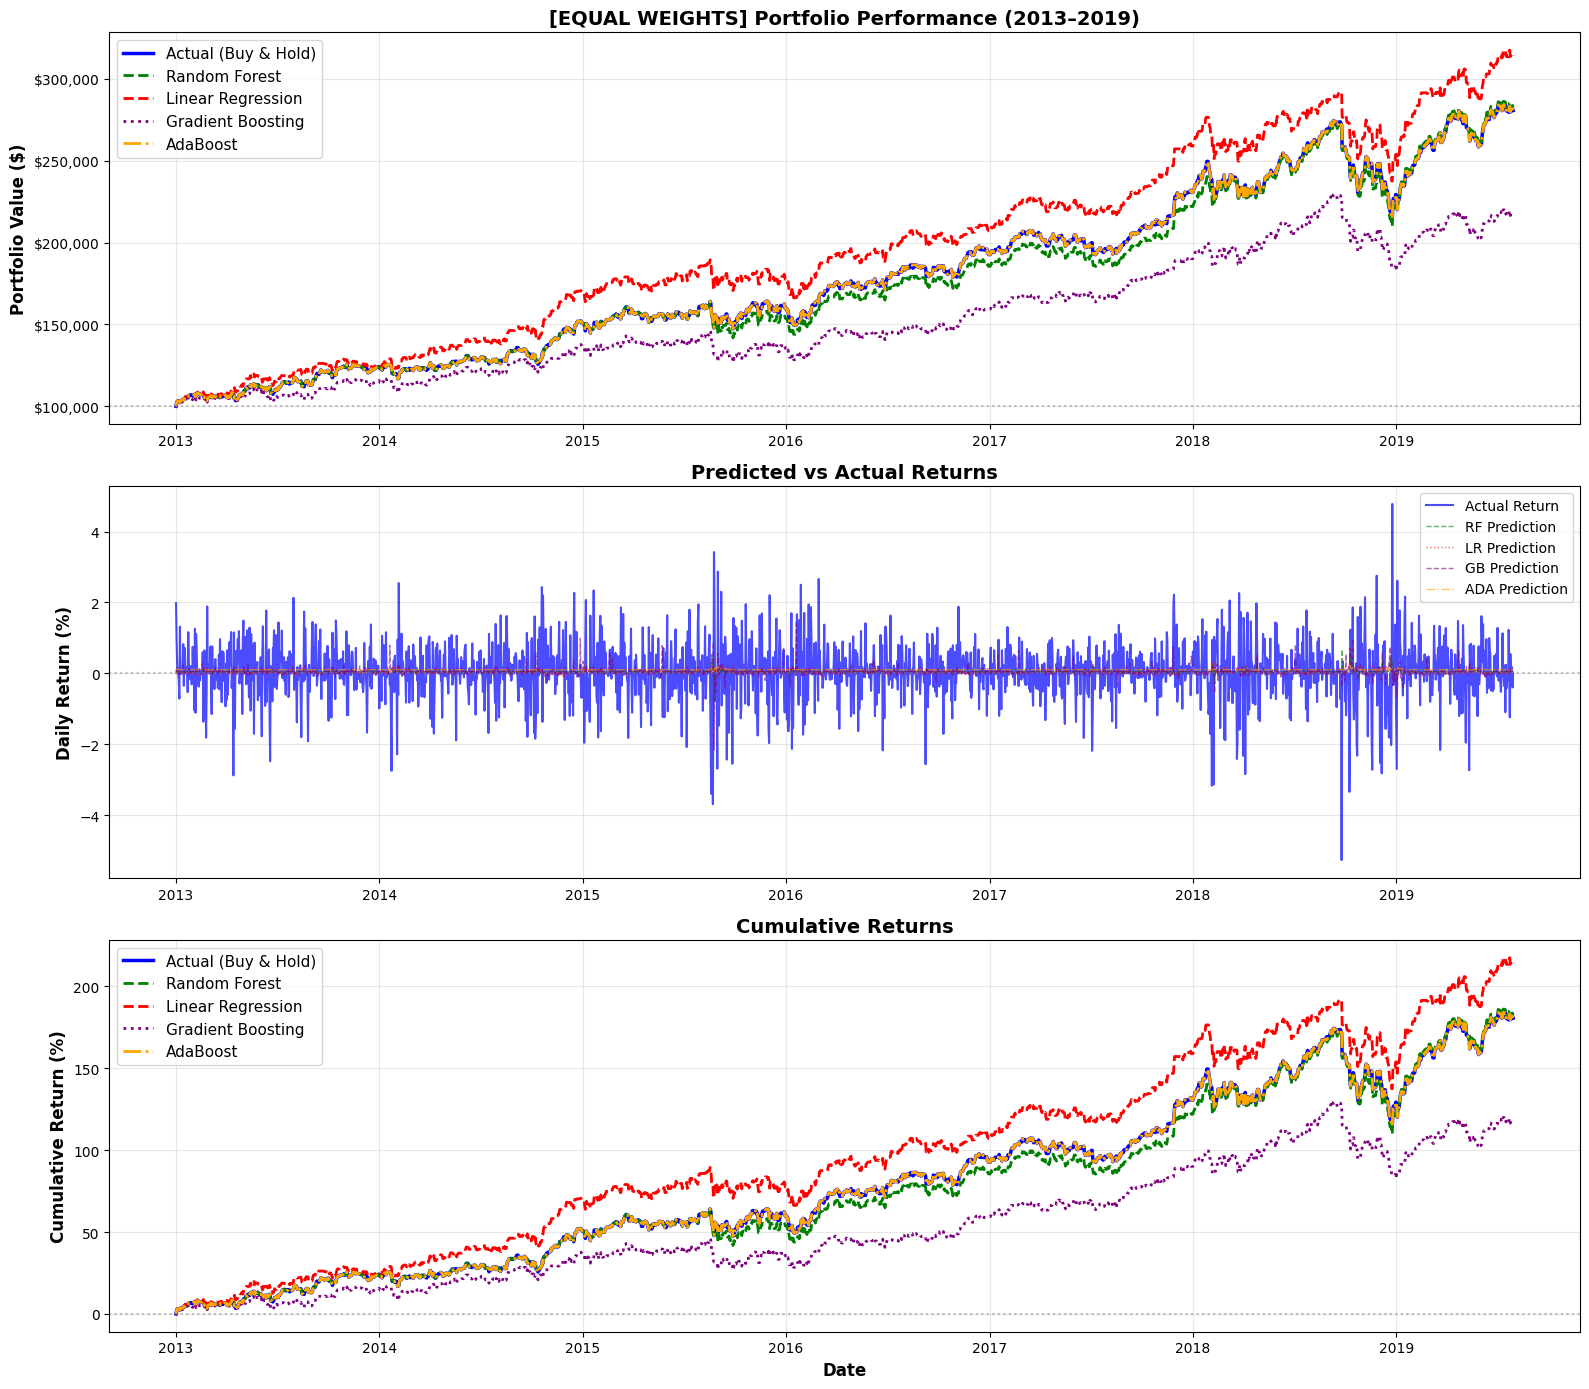


PORTFOLIO PERFORMANCE — EQUAL WEIGHTS

  Actual
    Final Value:       $280,655.97
    Total Return:      180.66%
    Annualized Return: 11.43%
    Volatility:        11.57%
    Sharpe Ratio:      0.9885
    Profit/Loss:       $180,655.97

  Random Forest
    Final Value:       $282,612.01
    Total Return:      182.61%
    Annualized Return: 11.52%
    Volatility:        11.41%
    Sharpe Ratio:      1.0089
    Profit/Loss:       $182,612.01

  Linear Regression
    Final Value:       $314,067.75
    Total Return:      214.07%
    Annualized Return: 12.76%
    Volatility:        10.90%
    Sharpe Ratio:      1.1704
    Profit/Loss:       $214,067.75

  Gradient Boosting
    Final Value:       $217,235.52
    Total Return:      117.24%
    Annualized Return: 8.48%
    Volatility:        10.46%
    Sharpe Ratio:      0.8106
    Profit/Loss:       $117,235.52

  AdaBoost
    Final Value:       $280,655.97
    Total Return:      180.66%
    Annualized Return: 11.43%
    Volatility:      

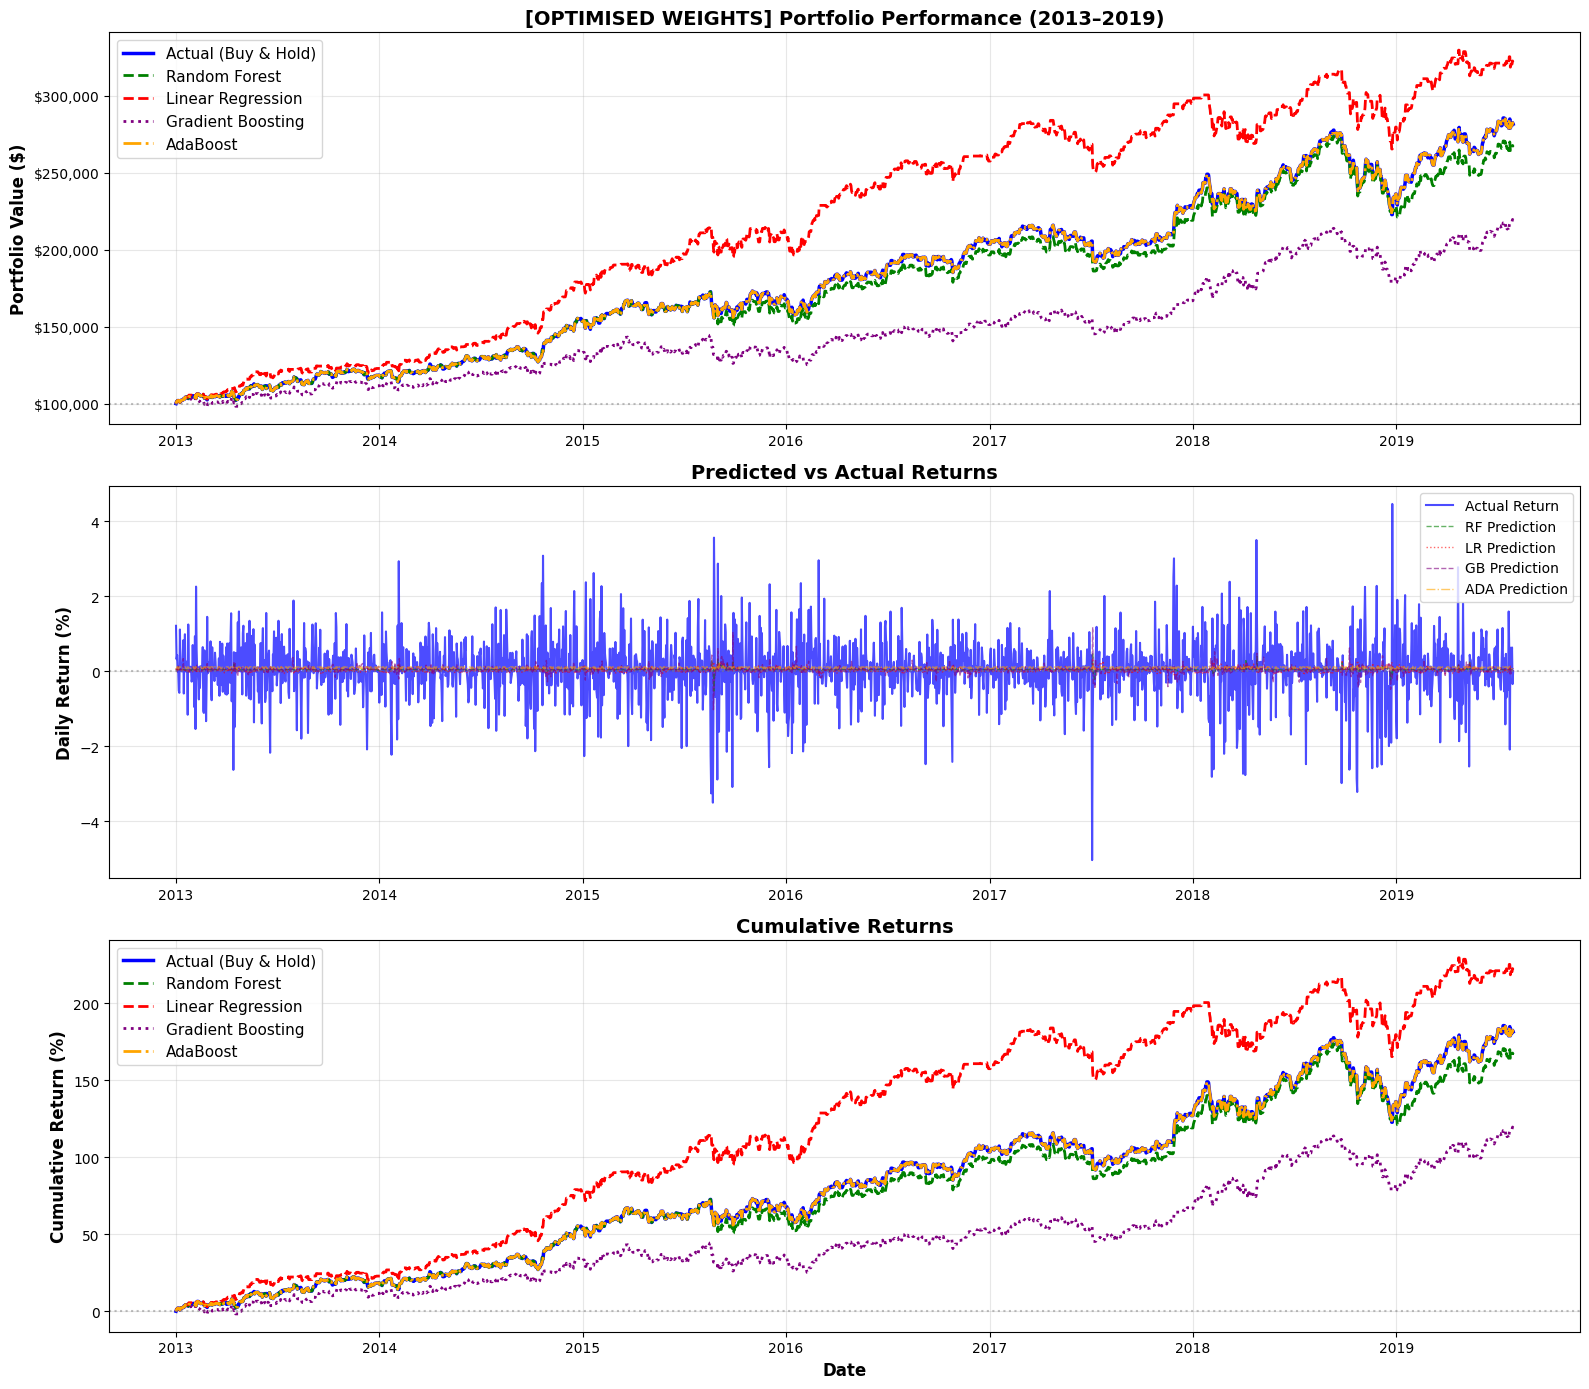


PORTFOLIO PERFORMANCE — OPTIMISED WEIGHTS

  Actual
    Final Value:       $281,539.32
    Total Return:      181.54%
    Annualized Return: 11.47%
    Volatility:        11.79%
    Sharpe Ratio:      0.9730
    Profit/Loss:       $181,539.32

  Random Forest
    Final Value:       $266,809.77
    Total Return:      166.81%
    Annualized Return: 10.84%
    Volatility:        11.58%
    Sharpe Ratio:      0.9367
    Profit/Loss:       $166,809.77

  Linear Regression
    Final Value:       $321,506.47
    Total Return:      221.51%
    Annualized Return: 13.03%
    Volatility:        10.52%
    Sharpe Ratio:      1.2393
    Profit/Loss:       $221,506.47

  Gradient Boosting
    Final Value:       $218,942.51
    Total Return:      118.94%
    Annualized Return: 8.57%
    Volatility:        10.76%
    Sharpe Ratio:      0.7966
    Profit/Loss:       $118,942.51

  AdaBoost
    Final Value:       $281,539.32
    Total Return:      181.54%
    Annualized Return: 11.47%
    Volatility:  

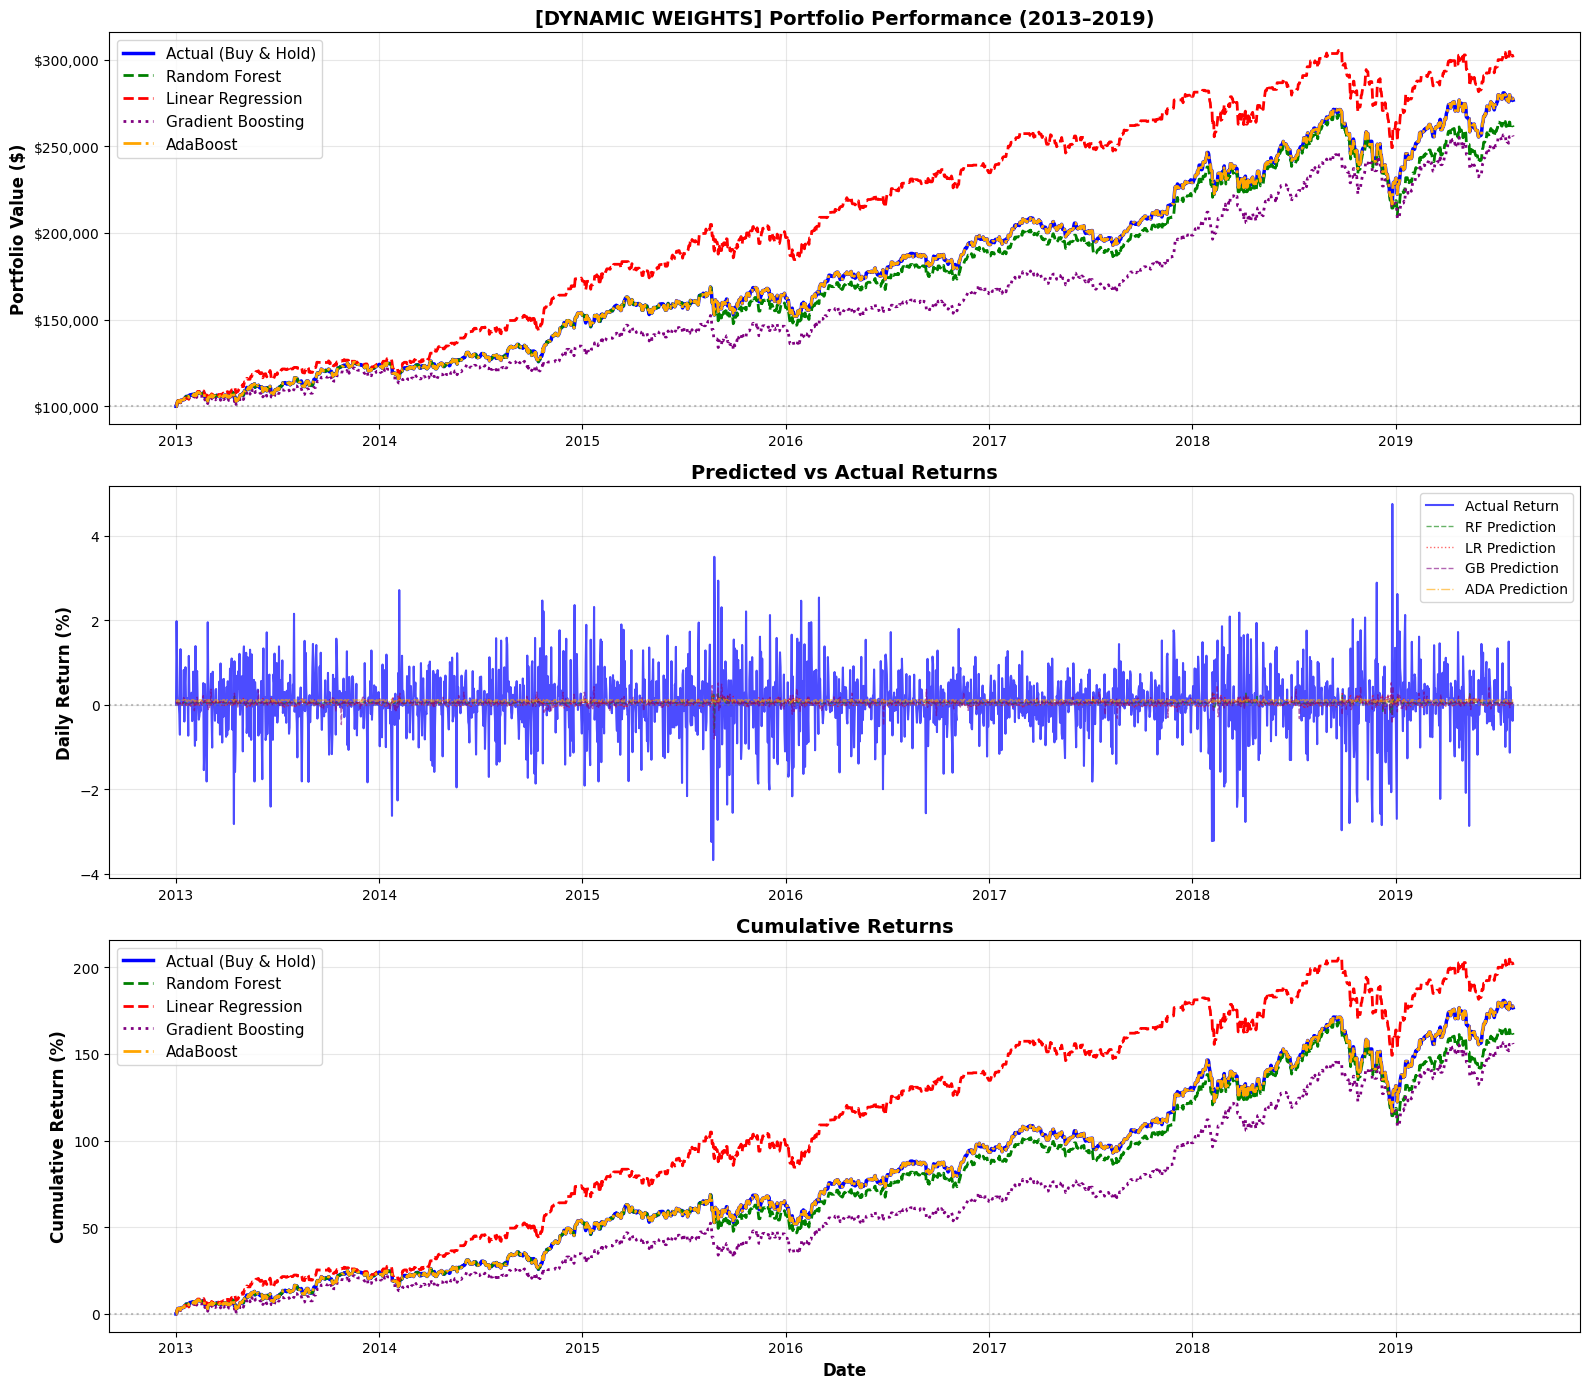


PORTFOLIO PERFORMANCE — DYNAMIC WEIGHTS

  Actual
    Final Value:       $276,554.92
    Total Return:      176.55%
    Annualized Return: 11.26%
    Volatility:        11.41%
    Sharpe Ratio:      0.9866
    Profit/Loss:       $176,554.92

  Random Forest
    Final Value:       $261,040.90
    Total Return:      161.04%
    Annualized Return: 10.59%
    Volatility:        11.20%
    Sharpe Ratio:      0.9454
    Profit/Loss:       $161,040.90

  Linear Regression
    Final Value:       $301,251.87
    Total Return:      201.25%
    Annualized Return: 12.26%
    Volatility:        10.30%
    Sharpe Ratio:      1.1907
    Profit/Loss:       $201,251.87

  Gradient Boosting
    Final Value:       $255,590.23
    Total Return:      155.59%
    Annualized Return: 10.34%
    Volatility:        10.54%
    Sharpe Ratio:      0.9816
    Profit/Loss:       $155,590.23

  AdaBoost
    Final Value:       $276,554.92
    Total Return:      176.55%
    Annualized Return: 11.26%
    Volatility:   

In [ ]:
initial_investment = 100_000

for label, actual_returns, rf_pred, lr_pred, gb_pred, ada_pred, test_index in [
    ('EQUAL WEIGHTS',     target_test_eq.values      / 100, rf_pred_eq,      lr_pred_eq,      gb_pred_eq,      ada_pred_eq,      features_test_eq.index),
    ('OPTIMISED WEIGHTS', target_test_opt.values      / 100, rf_pred_opt,     lr_pred_opt,     gb_pred_opt,     ada_pred_opt,     features_test_opt.index),
    ('DYNAMIC WEIGHTS',   target_test_dynamic.values  / 100, rf_pred_dynamic, lr_pred_dynamic, gb_pred_dynamic, ada_pred_dynamic, features_test_dynamic.index),
]:

    # Align index to actual_returns length — guards against imputation misalignment
    test_index = test_index[:len(actual_returns)]

    actual_portfolio = [initial_investment]
    rf_portfolio     = [initial_investment]
    lr_portfolio     = [initial_investment]
    gb_portfolio     = [initial_investment]
    ada_portfolio    = [initial_investment]

    for i, r in enumerate(actual_returns):
        actual_portfolio.append(actual_portfolio[-1] * (1 + r))
        rf_portfolio.append(rf_portfolio[-1]   * (1 + r) if rf_pred[i]  > 0 else rf_portfolio[-1])
        lr_portfolio.append(lr_portfolio[-1]   * (1 + r) if lr_pred[i]  > 0 else lr_portfolio[-1])
        gb_portfolio.append(gb_portfolio[-1]   * (1 + r) if gb_pred[i]  > 0 else gb_portfolio[-1])
        ada_portfolio.append(ada_portfolio[-1] * (1 + r) if ada_pred[i] > 0 else ada_portfolio[-1])

    portfolio_df = pd.DataFrame({
        'Actual':             actual_portfolio[:-1],
        'Random_Forest':      rf_portfolio[:-1],
        'Linear_Regression':  lr_portfolio[:-1],
        'Gradient_Boosting':  gb_portfolio[:-1],
        'AdaBoost':           ada_portfolio[:-1],
    }, index=test_index)

    # ── Plot ─────────────────────────────────────────────────
    fig, axes = plt.subplots(3, 1, figsize=(16, 14))

    plot_series = [
        ('Actual',            'Actual (Buy & Hold)', 'blue',   '-',  2.5),
        ('Random_Forest',     'Random Forest',       'green',  '--', 2.0),
        ('Linear_Regression', 'Linear Regression',   'red',    '--', 2.0),
        ('Gradient_Boosting', 'Gradient Boosting',   'purple', ':',  2.0),
        ('AdaBoost',          'AdaBoost',            'orange', '-.', 2.0),
    ]

    for col, lbl, color, style, lw in plot_series:
        axes[0].plot(portfolio_df.index, portfolio_df[col],
                     linewidth=lw, label=lbl, color=color, linestyle=style)
    axes[0].axhline(y=initial_investment, color='gray', linestyle=':', alpha=0.5)
    axes[0].set_ylabel('Portfolio Value ($)', fontsize=12, fontweight='bold')
    axes[0].set_title(f'[{label}] Portfolio Performance (2013–2019)', fontsize=14, fontweight='bold')
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

    pred_series = [
        (actual_returns * 100, 'Actual Return',  'blue',   '-',  1.5, 0.7),
        (rf_pred,              'RF Prediction',  'green',  '--', 1.0, 0.6),
        (lr_pred,              'LR Prediction',  'red',    ':',  1.0, 0.6),
        (gb_pred,              'GB Prediction',  'purple', '--', 1.0, 0.6),
        (ada_pred,             'ADA Prediction', 'orange', '-.', 1.0, 0.6),
    ]

    for data, lbl, color, style, lw, alpha in pred_series:
        axes[1].plot(test_index, data, linewidth=lw, alpha=alpha,
                     label=lbl, color=color, linestyle=style)
    axes[1].axhline(y=0, color='gray', linestyle=':', alpha=0.5)
    axes[1].set_ylabel('Daily Return (%)', fontsize=12, fontweight='bold')
    axes[1].set_title('Predicted vs Actual Returns', fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=10)
    axes[1].grid(True, alpha=0.3)

    for col, lbl, color, style, lw in plot_series:
        cum = ((portfolio_df[col] - initial_investment) / initial_investment) * 100
        axes[2].plot(portfolio_df.index, cum, linewidth=lw,
                     label=lbl, color=color, linestyle=style)
    axes[2].axhline(y=0, color='gray', linestyle=':', alpha=0.5)
    axes[2].set_xlabel('Date', fontsize=12, fontweight='bold')
    axes[2].set_ylabel('Cumulative Return (%)', fontsize=12, fontweight='bold')
    axes[2].set_title('Cumulative Returns', fontsize=14, fontweight='bold')
    axes[2].legend(fontsize=11)
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'portfolio_{label.lower().replace(" ", "_")}.png', dpi=300, bbox_inches='tight')
    plt.show()

    # ── Metrics ──────────────────────────────────────────────
    print("\n" + "="*80)
    print(f"PORTFOLIO PERFORMANCE — {label}")
    print("="*80)

    for strategy in ['Actual', 'Random_Forest', 'Linear_Regression', 'Gradient_Boosting', 'AdaBoost']:
        start_val  = portfolio_df[strategy].iloc[0]
        end_val    = portfolio_df[strategy].iloc[-1]
        total_ret  = (end_val - start_val) / start_val * 100
        daily_ret  = portfolio_df[strategy].pct_change().dropna()
        volatility = daily_ret.std() * np.sqrt(252) * 100
        years      = len(portfolio_df) / 252
        ann_ret    = ((end_val / start_val) ** (1 / years) - 1) * 100
        sharpe     = ann_ret / volatility if volatility > 0 else 0

        print(f"\n  {strategy.replace('_', ' ')}")
        print(f"    Final Value:       ${end_val:,.2f}")
        print(f"    Total Return:      {total_ret:.2f}%")
        print(f"    Annualized Return: {ann_ret:.2f}%")
        print(f"    Volatility:        {volatility:.2f}%")
        print(f"    Sharpe Ratio:      {sharpe:.4f}")
        print(f"    Profit/Loss:       ${end_val - initial_investment:,.2f}")

####I construct a fixed portfolio of 10 stocks using pre-optimised weights derived from historical data between 1993 and 2013, and simulate its performance over the out-of-sample test period from 2013 to 2019. Rather than passively holding the portfolio throughout the entire period, I overlay a daily market timing signal generated by my machine learning models — a Random Forest and a Linear Regression — which are trained to predict the next day's portfolio return. Each day, if my model predicts a positive return, I invest my entire capital into the fixed-weight portfolio and capture that day's actual return; if the model predicts a negative return, I exit the portfolio entirely and hold cash, avoiding that day's loss. This means I am not selecting individual stocks on a daily basis, but instead making a single all-or-nothing decision each day on whether to be invested in my pre-built portfolio or to sit in cash, with the goal of capturing the upside days while sidestepping the downside — effectively using my machine learning models as a market timing filter over a buy-and-hold foundation.

#Comparison between Equal weight, Optimum weight and Dynamic weight.

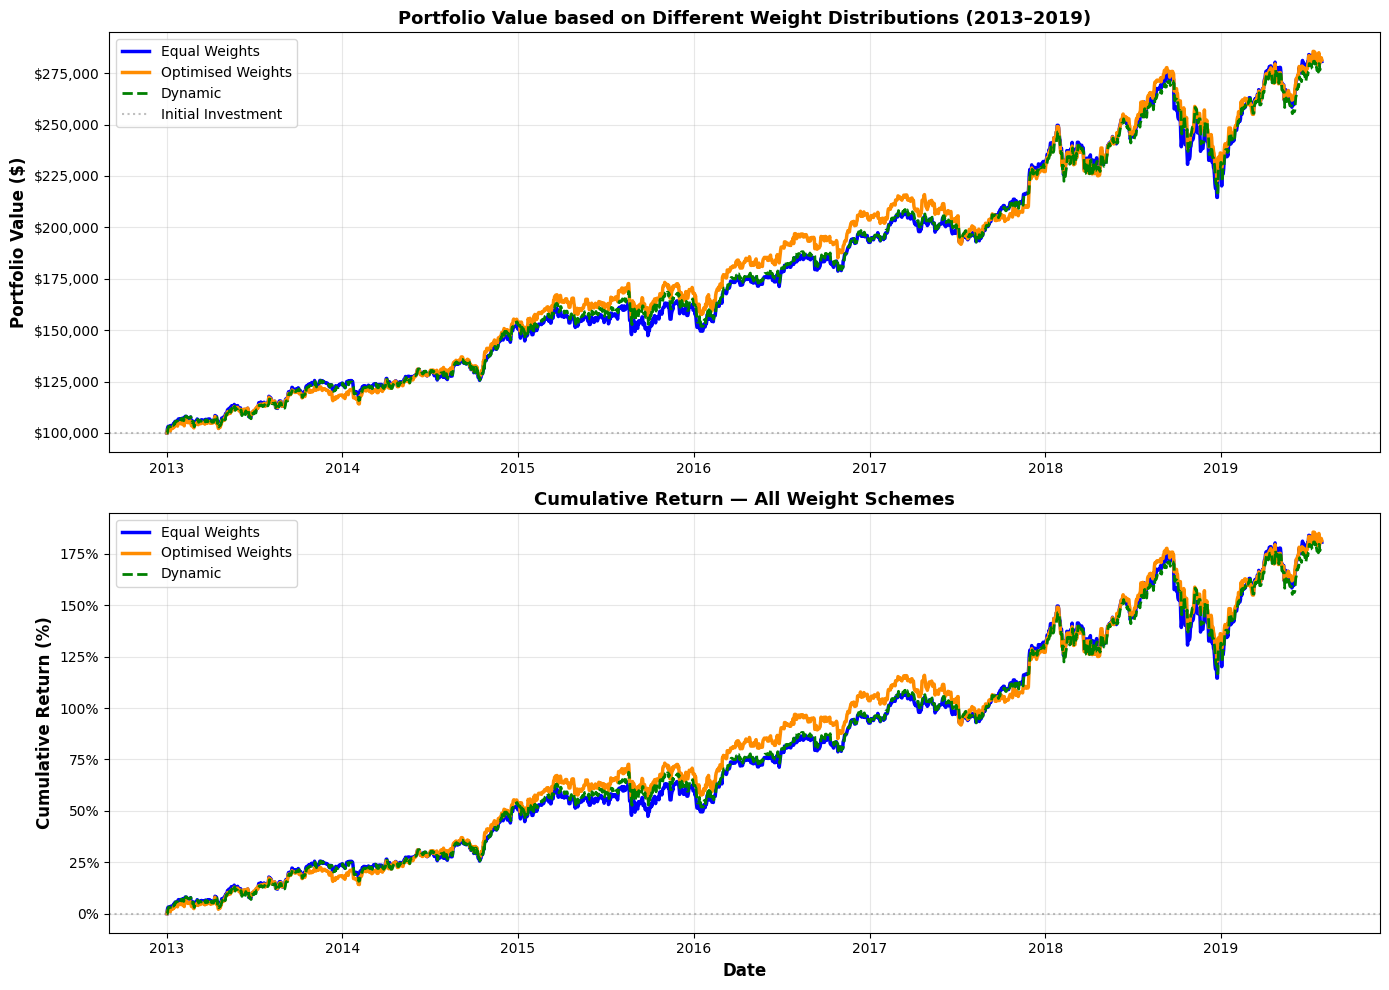


BUY & HOLD COMPARISON — ALL WEIGHT SCHEMES
Scheme                       Final Value   Total Ret   Ann Ret      Vol   Sharpe
---------------------------------------------------------------------------
Equal Weights              $  280,655.97     180.66%    11.43%   11.57%   0.9885
Optimised Weights          $  281,539.32     181.54%    11.47%   11.79%   0.9730
Dynamic                    $  276,554.92     176.55%    11.26%   11.41%   0.9866


In [44]:
# ── COLLECT ACTUAL PORTFOLIOS ACROSS ALL SCHEMES ─────────────────────────────
actual_portfolios = {}

for label, actual_returns, rf_pred, lr_pred, gb_pred, ada_pred, test_index in [
    ('Equal Weights',          target_test_eq.values      / 100, rf_pred_eq,      lr_pred_eq,      gb_pred_eq,      ada_pred_eq,      features_test_eq.index),
    ('Optimised Weights',      target_test_opt.values      / 100, rf_pred_opt,     lr_pred_opt,     gb_pred_opt,     ada_pred_opt,     features_test_opt.index),
    ('Dynamic',     target_test_dynamic.values  / 100, rf_pred_dynamic, lr_pred_dynamic, gb_pred_dynamic, ada_pred_dynamic, features_test_dynamic.index),
]:
    test_index   = test_index[:len(actual_returns)]
    port         = [initial_investment]
    for r in actual_returns:
        port.append(port[-1] * (1 + r))
    actual_portfolios[label] = pd.Series(port[:-1], index=test_index)


# ── PLOT — ACTUAL BUY & HOLD ONLY, ALL WEIGHT SCHEMES ────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

plot_config = [
    ('Equal Weights',         'blue',       '-',  2.5),
    ('Optimised Weights',     'darkorange',  '-',  2.5),
    ('Dynamic',    'green',       '--', 2.0)
]

# ── subplot 1: portfolio value ────────────────────────────────
for label, color, style, lw in plot_config:
    axes[0].plot(
        actual_portfolios[label].index,
        actual_portfolios[label].values,
        label=label, color=color, linestyle=style, linewidth=lw
    )

axes[0].axhline(y=initial_investment, color='gray', linestyle=':', alpha=0.5, label='Initial Investment')
axes[0].set_ylabel('Portfolio Value ($)', fontsize=12, fontweight='bold')
axes[0].set_title('Portfolio Value based on Different Weight Distributions (2013–2019)',
                  fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10, loc='upper left')
axes[0].grid(True, alpha=0.3)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# ── subplot 2: cumulative return % ───────────────────────────
for label, color, style, lw in plot_config:
    cum = ((actual_portfolios[label] - initial_investment) / initial_investment) * 100
    axes[1].plot(
        actual_portfolios[label].index,
        cum,
        label=label, color=color, linestyle=style, linewidth=lw
    )

axes[1].axhline(y=0, color='gray', linestyle=':', alpha=0.5)
axes[1].set_xlabel('Date', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Cumulative Return (%)', fontsize=12, fontweight='bold')
axes[1].set_title('Cumulative Return — All Weight Schemes', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10, loc='upper left')
axes[1].grid(True, alpha=0.3)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

plt.tight_layout()
plt.savefig('actual_portfolio_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


# ── SUMMARY TABLE ─────────────────────────────────────────────
print("\n" + "="*75)
print("BUY & HOLD COMPARISON — ALL WEIGHT SCHEMES")
print("="*75)
print(f"{'Scheme':<26} {'Final Value':>13} {'Total Ret':>11} {'Ann Ret':>9} {'Vol':>8} {'Sharpe':>8}")
print("-"*75)

for label, color, style, lw in plot_config:
    series     = actual_portfolios[label]
    end_val    = series.iloc[-1]
    total_ret  = (end_val - initial_investment) / initial_investment * 100
    daily_ret  = series.pct_change().dropna()
    volatility = daily_ret.std() * np.sqrt(252) * 100
    years      = len(series) / 252
    ann_ret    = ((end_val / initial_investment) ** (1 / years) - 1) * 100
    sharpe     = ann_ret / volatility if volatility > 0 else 0

    print(f"{label:<26} ${end_val:>12,.2f} {total_ret:>10.2f}% {ann_ret:>8.2f}% {volatility:>7.2f}% {sharpe:>8.4f}")

print("="*75)